# Лабораторная работа: Математический анализ и матричное исчисление

## 1. Суммы, индексы и матричная запись

### Задание 1.1. От суммы к матрице

**[Бумага] / [Markdown]**
Даны матрицы:
$$A = \begin{pmatrix} 1 & 2 \\ -1 & 0 \\ 3 & 1 \end{pmatrix} \in \mathbb{R}^{3 \times 2}, \quad B = \begin{pmatrix} 2 & 1 & 1 \\ -1 & 0 & 2 \end{pmatrix} \in \mathbb{R}^{2 \times 3}$$

Размер результата $C = AB$: $3 \times 3$.
Формула элемента: $C_{ij} = \sum_{k=1}^2 A_{ik} B_{kj}$.

- **Свободные индексы:** $i \in \{1,2,3\}$, $j \in \{1,2,3\}$. Они остаются у результата и определяют его размерность.
- **Суммируемый (фиктивный) индекс:** $k \in \{1,2\}$. Он пробегает допустимые значения и исчезает после суммирования.

**[Интерпретация]**
Индекс $k$ отсутствует в обозначении $C_{ij}$, так как по нему производится свёртка (суммирование), и он "исчезает" в результате. Поменять местами $j$ и $k$ нельзя, так как $j$ — свободный индекс, определяющий столбец результата, а $k$ — индекс внутренней размерности, по которому идёт умножение строки на столбец (размерности должны совпадать: $2$ и $2$).

In [1]:
import numpy as np

# Задание 1.1
A = np.array([[1, 2], [-1, 0], [3, 1]])
B = np.array([[2, 1, 1], [-1, 0, 2]])

# 1. Матричное произведение
C_matrix = A @ B

# 2. Тройной цикл
C_loop = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        for k in range(2):
            C_loop[i, j] += A[i, k] * B[k, j]

print("Результат A @ B:\n", C_matrix)
print("Результат через циклы:\n", C_loop)
print("Совпадают:", np.allclose(C_matrix, C_loop))

Результат A @ B:
 [[ 0  1  5]
 [-2 -1 -1]
 [ 5  3  5]]
Результат через циклы:
 [[ 0.  1.  5.]
 [-2. -1. -1.]
 [ 5.  3.  5.]]
Совпадают: True


### Задание 1.2. Три индекса и две свёртки

**[Бумага] / [Markdown]**
Тензор $S_{ntk}$, матрицы $W_{kd}$, $V_{dc}$.
$$L_{nc} = \sum_{t=1}^2 \sum_{k=1}^3 \sum_{d=1}^2 S_{ntk} W_{kd} V_{dc}$$

Размеры объектов:
- $S \in \mathbb{R}^{2 \times 2 \times 3}$ (индексы $n, t, k$)
- $W \in \mathbb{R}^{3 \times 2}$ (индексы $k, d$)
- $V \in \mathbb{R}^{2 \times 2}$ (индексы $d, c$)
- Результат $L \in \mathbb{R}^{2 \times 2}$ (индексы $n, c$).

**Свободные индексы:** $n, c$. Они остаются у результата.
**Суммируемые индексы:** $t, k, d$. Они пробегают свои значения и исчезают.
В нотации Эйнштейна: $L_{nc} = S_{ntk} W_{kd} V_{dc}$.

**[Интерпретация]**
Вычисление можно разбить на два шага с промежуточной матрицей $E_{nd}$:
1. $E_{nd} = \sum_{t=1}^2 \sum_{k=1}^3 S_{ntk} W_{kd}$ (свёртка тензора и матрицы, размер $2 \times 2$)
2. $L_{nc} = \sum_{d=1}^2 E_{nd} V_{dc}$ (матричное произведение, размер $2 \times 2$)

*Примечание: В условии матрицы $S$ визуально представлены как $3 \times 2$, но пределы суммирования указывают на $t \in \{1,2\}, k \in \{1,2,3\}$. В коде мы транспонируем их к размеру $2 \times 3$, чтобы строго соответствовать математической записи.*

In [2]:
# Задание 1.2 и 1.3
# Инициализация данных (с учётом транспонирования для соответствия пределам суммирования)
S_pdf = [
    np.array([[1, 0], [0, 0], [1, 0]]),
    np.array([[0, 1], [0, 0], [0, 1]])
]
S = np.array([s.T for s in S_pdf]) # Теперь размер (2, 2, 3)

W = np.array([[1, 0], [0, 2], [1, -1]]) # 3x2
V = np.array([[1, -1], [2, 1]])         # 2x2

# 1. Вложенные циклы
L_loop = np.zeros((2, 2))
for n in range(2):
    for c in range(2):
        for t in range(2):
            for k in range(3):
                for d in range(2):
                    L_loop[n, c] += S[n, t, k] * W[k, d] * V[d, c]

# 2. Через промежуточную матрицу E (ручное матричное умножение)
E = np.zeros((2, 2))
for n in range(2):
    for d in range(2):
        for t in range(2):
            for k in range(3):
                E[n, d] += S[n, t, k] * W[k, d]
L_matrix = E @ V

# 3. Один np.einsum
L_einsum1 = np.einsum('ntk,kd,dc->nc', S, W, V)

# 4. Два последовательных np.einsum
E_einsum = np.einsum('ntk,kd->nd', S, W)
L_einsum2 = np.einsum('nd,dc->nc', E_einsum, V)

print("L_loop:\n", L_loop)
print("L_matrix:\n", L_matrix)
print("L_einsum1:\n", L_einsum1)
print("L_einsum2:\n", L_einsum2)
print("Все методы совпадают:", np.allclose(L_loop, L_matrix) and np.allclose(L_matrix, L_einsum1) and np.allclose(L_einsum1, L_einsum2))

L_loop:
 [[ 0. -3.]
 [ 0. -3.]]
L_matrix:
 [[ 0. -3.]
 [ 0. -3.]]
L_einsum1:
 [[ 0 -3]
 [ 0 -3]]
L_einsum2:
 [[ 0 -3]
 [ 0 -3]]
Все методы совпадают: True


### Задание 1.3. Интерпретация

**[Интерпретация]**
Строки индексов для `einsum`:
- `'ntk,kd,dc->nc'`: прямая трансляция формулы Эйнштейна.
- `'ntk,kd->nd'`: свёртка тензора $S$ и матрицы $W$ по индексам $t$ и $k$.
- `'nd,dc->nc'`: стандартное матричное произведение $E$ и $V$.

Совпадение четырёх реализаций подтверждает, что индексы и размерности выбраны верно, а логика свёрток не содержит ошибок. Однако это не заменяет проверку размерностей *до* запуска: если бы мы ошиблись в пределах суммирования (например, $t$ до 3 вместо 2), циклы и `einsum` выдали бы ошибку или неверный результат, и слепое доверие к "совпадению" внутри кода могло бы ввести в заблуждение.

## 2. Функции одной переменной

### Задание 2.1. Производная как предел и как численный оператор

**[Бумага]**
Дано: $f(x) = e^x$, $x_0 = 1$.
Точная производная: $f'(x) = e^x \implies f'(1) = e \approx 2.71828$.
Уравнение касательной: $y = f(x_0) + f'(x_0)(x - x_0) = e + e(x - 1) = ex$.

**[Markdown]**
Три формулы конечных разностей:
- Прямая: $D_+(h) = \frac{f(x_0+h) - f(x_0)}{h}$ (ошибка $O(h)$)
- Обратная: $D_-(h) = \frac{f(x_0) - f(x_0-h)}{h}$ (ошибка $O(h)$)
- Центральная: $D_0(h) = \frac{f(x_0+h/2) - f(x_0-h/2)}{h}$ (ошибка $O(h^2)$)

Все три выражения стремятся к $f'(x_0)$ при $h \to 0$ по определению производной. Однако при конечном $h$ центральная разность имеет ошибку второго порядка малости, поэтому она точнее прямой и обратной при одинаковом $h$.

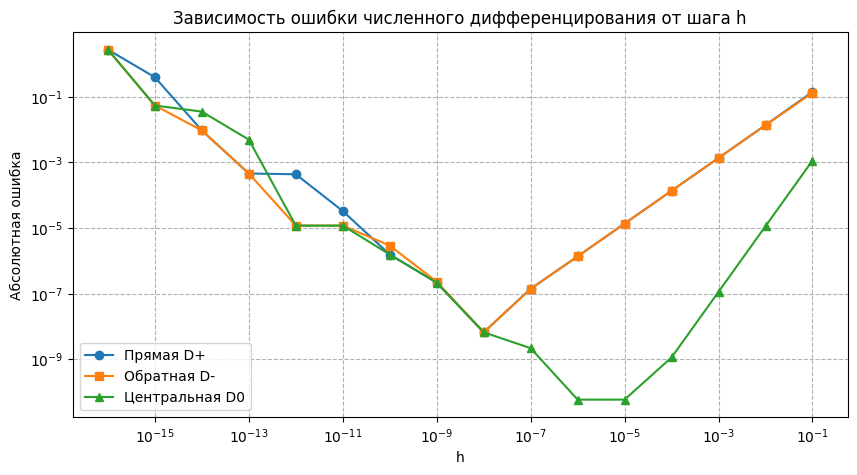

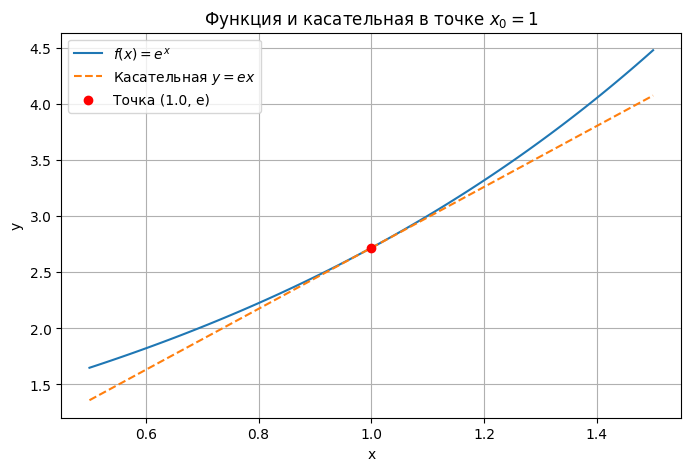

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 2.1
x0 = 1.0
f = lambda x: np.exp(x)
exact_deriv = np.exp(x0)

# Диапазон h от 10^-1 до 10^-16
h_values = np.logspace(-1, -16, 16)

errors_plus = []
errors_minus = []
errors_central = []

for h in h_values:
    D_plus = (f(x0 + h) - f(x0)) / h
    D_minus = (f(x0) - f(x0 - h)) / h
    D_central = (f(x0 + h/2) - f(x0 - h/2)) / h
    
    errors_plus.append(abs(D_plus - exact_deriv))
    errors_minus.append(abs(D_minus - exact_deriv))
    errors_central.append(abs(D_central - exact_deriv))

# График ошибок
plt.figure(figsize=(10, 5))
plt.loglog(h_values, errors_plus, 'o-', label='Прямая D+')
plt.loglog(h_values, errors_minus, 's-', label='Обратная D-')
plt.loglog(h_values, errors_central, '^-', label='Центральная D0')
plt.xlabel('h')
plt.ylabel('Абсолютная ошибка')
plt.title('Зависимость ошибки численного дифференцирования от шага h')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

# График функции и касательной
x_plot = np.linspace(0.5, 1.5, 100)
y_plot = f(x_plot)
tangent_plot = exact_deriv * x_plot # так как y = e*x

plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_plot, label='$f(x) = e^x$')
plt.plot(x_plot, tangent_plot, '--', label=f'Касательная $y = ex$')
plt.scatter([x0], [f(x0)], color='red', zorder=5, label=f'Точка ({x0}, e)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Функция и касательная в точке $x_0 = 1$')
plt.legend()
plt.grid(True)
plt.show()

**[Интерпретация]**
На графике ошибок видно, что при уменьшении $h$ от $10^{-1}$ до $10^{-8}$ ошибка падает (центральная разность падает быстрее, как и ожидается из $O(h^2)$). 
Однако при $h < 10^{-8}$ ошибка начинает **расти**. Это происходит из-за **катастрофической отмены** (catastrophic cancellation): при вычитании двух очень близких чисел $f(x_0+h)$ и $f(x_0)$ значащие цифры теряются, и на первый план выходит ошибка округления машинной арифметики (machine epsilon $\approx 10^{-16}$). Оптимальный шаг $h$ для двойной точности находится в районе $10^{-8}$.

### Задание 2.2. Правила дифференцирования

**[Бумага]**
1) $y = 2x^3 - 5x^2 + 7x + 4$  
   $y' = 6x^2 - 10x + 7 \implies y'(1) = 6 - 10 + 7 = 3$. (Правило суммы и степенной функции)
2) $y = x^2 e^x$  
   $y' = 2x e^x + x^2 e^x = e^x(2x + x^2) \implies y'(1) = e(2 + 1) = 3e \approx 8.1548$. (Правило произведения)
3) $y = (2x^2 + 5)^2$  
   $y' = 2(2x^2 + 5) \cdot (4x) = 8x(2x^2 + 5) \implies y'(1) = 8 \cdot 1 \cdot 7 = 56$. (Цепное правило)
4) $y = \ln(2x^3 + 3x^2)$  
   $y' = \frac{1}{2x^3 + 3x^2} \cdot (6x^2 + 6x) = \frac{6x(x + 1)}{x^2(2x + 3)} \implies y'(1) = \frac{12}{5} = 2.4$. (Цепное правило)

**[Markdown]**
В пункте 3: внешняя функция $g(u) = u^2$, внутренняя $u(x) = 2x^2 + 5$.  
В пункте 4: внешняя функция $g(u) = \ln(u)$, внутренняя $u(x) = 2x^3 + 3x^2$.

In [4]:
# Задание 2.2
h_check = 1e-5

funcs = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2)
]

exact_derivs = [3.0, 3*np.exp(1), 56.0, 2.4]

print("Функция | Точная производная | Численная (центральная) | Ошибка")
print("-" * 65)
for i, f_i in enumerate(funcs):
    num_deriv = (f_i(1 + h_check/2) - f_i(1 - h_check/2)) / h_check
    error = abs(num_deriv - exact_derivs[i])
    print(f"   {i+1}    | {exact_derivs[i]:<18.6f} | {num_deriv:<21.6f} | {error:.2e}")

Функция | Точная производная | Численная (центральная) | Ошибка
-----------------------------------------------------------------
   1    | 3.000000           | 3.000000              | 2.42e-10
   2    | 8.154845           | 8.154845              | 2.65e-10
   3    | 56.000000          | 56.000000             | 7.22e-10
   4    | 2.400000           | 2.400000              | 4.68e-11


### Задание 2.3. Дифференциал и граница дифференцируемости

**[Бумага]**
1. $y = \ln(1 + x^2)$.  
   $y' = \frac{2x}{1 + x^2}$. В точке $x = 1$: $y'(1) = \frac{2}{2} = 1$.  
   Дифференциал: $dy = y'(1)dx = 1 \cdot 0.02 = 0.02$.  
   Точное изменение: $\Delta y = \ln(1 + 1.02^2) - \ln(1 + 1^2) = \ln(2.0404) - \ln(2) \approx 0.71310 - 0.69315 = 0.01995$.

2. $r(x) = \max(0, x)$ в точке $x = 0$.  
   Левая производная: $r'_-(0) = \lim_{h \to 0^-} \frac{0 - 0}{h} = 0$.  
   Правая производная: $r'_+(0) = \lim_{h \to 0^+} \frac{h - 0}{h} = 1$.

**[Markdown]**
Для существования обычной производной необходимо и достаточно, чтобы левый и правый пределы отношения приращения функции к приращению аргумента совпадали. В случае $r(x)$ в нуле они равны $0$ и $1$, следовательно, функция не дифференцируема в этой точке (имеет "излом").

Приближённое изменение (dy): 0.02000
Точное изменение (Δy):       0.02000
Погрешность:                 1.31e-06

Центральная разность для ReLU в x=0 при h=0.0001: 0.5


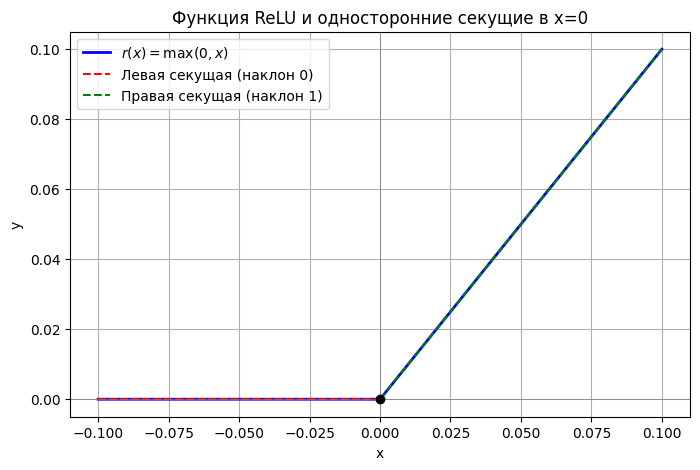

In [6]:
# Задание 2.3
# 1. Проверка дифференциала
x_start = 1.0
dx = 0.02
dy_approx = (2 * x_start / (1 + x_start**2)) * dx
dy_exact = np.log(1 + (x_start + dx)**2) - np.log(1 + x_start**2)

print(f"Приближённое изменение (dy): {dy_approx:.5f}")
print(f"Точное изменение (Δy):       {dy_exact:.5f}")
print(f"Погрешность:                 {abs(dy_approx - dy_exact):.2e}\n")

# 2. Исследование r(x) = max(0, x)
r = lambda x: np.maximum(0, x)
h_relu = 1e-4

# Центральная разность в нуле
central_r = (r(h_relu/2) - r(-h_relu/2)) / h_relu
print(f"Центральная разность для ReLU в x=0 при h={h_relu}: {central_r}")

# Построение графика
x_relu = np.linspace(-0.1, 0.1, 100)
y_relu = r(x_relu)

plt.figure(figsize=(8, 5))
# ИСПРАВЛЕНИЕ: добавлен префикс r перед строкой с LaTeX
plt.plot(x_relu, y_relu, 'b-', linewidth=2, label=r'$r(x) = \max(0, x)$')
# Левая секущая
plt.plot([-0.1, 0], [0, 0], 'r--', label='Левая секущая (наклон 0)')
# Правая секущая
plt.plot([0, 0.1], [0, 0.1], 'g--', label='Правая секущая (наклон 1)')
plt.scatter([0], [0], color='black', zorder=5)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.title('Функция ReLU и односторонние секущие в x=0')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

**[Интерпретация]**
1. Линейное приближение через дифференциал ($0.02$) очень близко к точному изменению ($0.01995$), что подтверждает корректность использования дифференциала для малых приращений.
2. Центральная разность для $r(x)$ в нуле возвращает значение $0.5$ (среднее арифметическое левой и правой производных). Это опасная ловушка: численный метод "не знает" о том, что функция не дифференцируема, и просто усредняет наклоны слева и справа. Поэтому слепая проверка центральной разностью может замаскировать наличие "излома" (недифференцируемости), и для таких функций требуется специальный анализ (как мы сделали аналитически).

## 3. Частные производные, градиент и дифференциал

### Задание 3.1. Полный дифференциал многочлена

**[Бумага]**
Дана функция: $z = 5x^3 + 2x^2y^4 - 6x + 9y$

**Частные производные:**
- $\frac{\partial z}{\partial x} = 15x^2 + 4xy^4 - 6$ (y считаем константой)
- $\frac{\partial z}{\partial y} = 8x^2y^3 + 9$ (x считаем константой)

**Градиент** (вектор-столбец):
$$\nabla z(x, y) = \begin{pmatrix} 15x^2 + 4xy^4 - 6 \\ 8x^2y^3 + 9 \end{pmatrix}$$

**Значение градиента в точке $(1, -1)$:**
- $\frac{\partial z}{\partial x}(1, -1) = 15(1)^2 + 4(1)(-1)^4 - 6 = 15 + 4 - 6 = 13$
- $\frac{\partial z}{\partial y}(1, -1) = 8(1)^2(-1)^3 + 9 = -8 + 9 = 1$

$$\nabla z(1, -1) = \begin{pmatrix} 13 \\ 1 \end{pmatrix}$$

**Полный дифференциал:**
$$dz = \frac{\partial z}{\partial x}dx + \frac{\partial z}{\partial y}dy$$

В раскрытом виде:
$$dz = (15x^2 + 4xy^4 - 6)dx + (8x^2y^3 + 9)dy$$

In [7]:
import numpy as np

# Задание 3.1
def z_func(x, y):
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y

def grad_z_exact(x, y):
    dz_dx = 15*x**2 + 4*x*y**4 - 6
    dz_dy = 8*x**2*y**3 + 9
    return np.array([dz_dx, dz_dy])

def central_gradient(f, x, y, h=1e-5):
    dz_dx = (f(x + h/2, y) - f(x - h/2, y)) / h
    dz_dy = (f(x, y + h/2) - f(x, y - h/2)) / h
    return np.array([dz_dx, dz_dy])

# Точка для проверки
x0, y0 = 1, -1

grad_exact = grad_z_exact(x0, y0)
grad_numerical = central_gradient(z_func, x0, y0, h=1e-5)

print(f"Аналитический градиент в точке ({x0}, {y0}):")
print(grad_exact)
print(f"\nЧисленный градиент (h=1e-5):")
print(grad_numerical)
print(f"\nНорма ошибки: {np.linalg.norm(grad_exact - grad_numerical):.2e}")

Аналитический градиент в точке (1, -1):
[13  1]

Численный градиент (h=1e-5):
[13.  1.]

Норма ошибки: 2.52e-10


**[Интерпретация]**
Коэффициент при $dx$ в полном дифференциале — это первая компонента градиента ($\frac{\partial z}{\partial x}$), а коэффициент при $dy$ — вторая компонента ($\frac{\partial z}{\partial y}$).

Это не случайно: полный дифференциал можно записать компактно как скалярное произведение:
$$dz = \nabla z^T \begin{pmatrix} dx \\ dy \end{pmatrix} = \nabla z \cdot d\mathbf{r}$$

Таким образом, градиент — это вектор коэффициентов линейного приближения, показывающий, как функция реагирует на малые изменения каждой координаты.

### Задание 3.2. Локальная плоскость вместо касательной

**[Бумага]**
Дана функция: $f(x, y) = x^2 + xy + 2y^2 - 3x + 1$, точка $x_0 = (1, -1)^T$

**Градиент:**
- $\frac{\partial f}{\partial x} = 2x + y - 3$
- $\frac{\partial f}{\partial y} = x + 4y$

В точке $(1, -1)$:
- $\frac{\partial f}{\partial x}(1, -1) = 2(1) + (-1) - 3 = 2 - 1 - 3 = -2$
- $\frac{\partial f}{\partial y}(1, -1) = 1 + 4(-1) = 1 - 4 = -3$

$$\nabla f(1, -1) = \begin{pmatrix} -2 \\ -3 \end{pmatrix}$$

**Значение функции:**
$f(1, -1) = 1^2 + 1(-1) + 2(-1)^2 - 3(1) + 1 = 1 - 1 + 2 - 3 + 1 = 0$

**Линейная модель (касательная плоскость):**
$$f(\mathbf{x}_0 + \Delta\mathbf{x}) \approx f(\mathbf{x}_0) + \nabla f(\mathbf{x}_0)^T \Delta\mathbf{x}$$
$$f(x_0 + \Delta x, y_0 + \Delta y) \approx 0 + (-2)\Delta x + (-3)\Delta y$$

**[Markdown]**
Для $\Delta\mathbf{x} = (0.01, -0.02)^T$:
- Прогноз изменения: $\Delta f \approx (-2)(0.01) + (-3)(-0.02) = -0.02 + 0.06 = 0.04$
- Прогноз нового значения: $f \approx 0 + 0.04 = 0.04$

Значение функции в точке (1, -1): 0
Градиент: [-2 -3]

Приращение: Δx = 0.01, Δy = -0.02
Прогноз (линейная модель): 0.040000
Точное значение: 0.040700
Ошибка аппроксимации: 7.00e-04


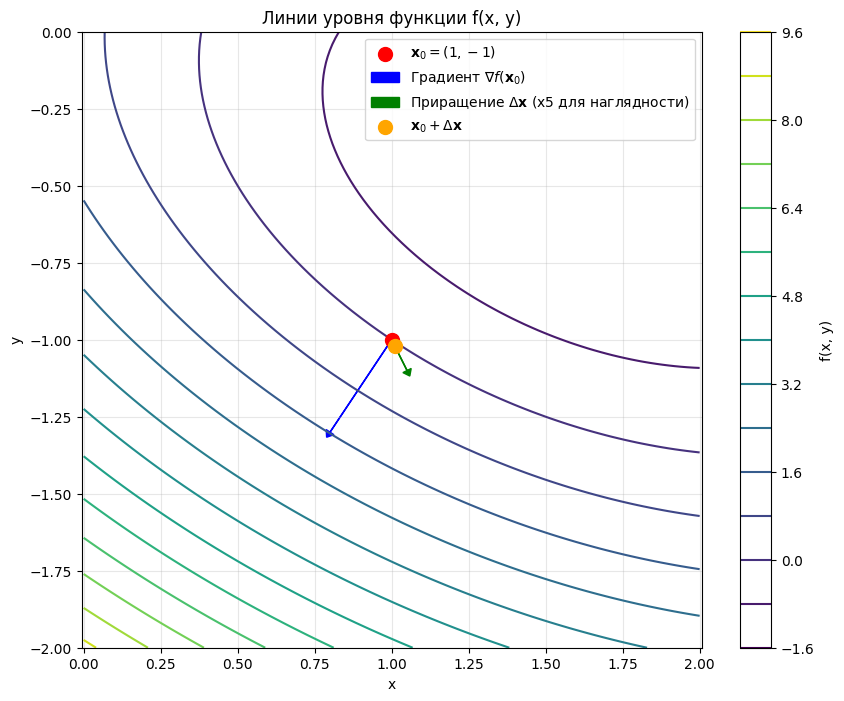

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 3.2
def f_func(x, y):
    return x**2 + x*y + 2*y**2 - 3*x + 1

def grad_f_exact(x, y):
    df_dx = 2*x + y - 3
    df_dy = x + 4*y
    return np.array([df_dx, df_dy])

# Точка и приращение
x0, y0 = 1, -1
dx, dy = 0.01, -0.02

f_x0 = f_func(x0, y0)
grad_f = grad_f_exact(x0, y0)

# Прогноз через линейную модель
delta_x = np.array([dx, dy])
f_approx = f_x0 + grad_f @ delta_x

# Точное значение
f_exact = f_func(x0 + dx, y0 + dy)

print(f"Значение функции в точке (1, -1): {f_x0}")
print(f"Градиент: {grad_f}")
print(f"\nПриращение: Δx = {dx}, Δy = {dy}")
print(f"Прогноз (линейная модель): {f_approx:.6f}")
print(f"Точное значение: {f_exact:.6f}")
print(f"Ошибка аппроксимации: {abs(f_approx - f_exact):.2e}")

# Построение линий уровня
x_range = np.linspace(0, 2, 100)
y_range = np.linspace(-2, 0, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = f_func(X, Y)

plt.figure(figsize=(10, 8))
contour = plt.contour(X, Y, Z, levels=15, cmap='viridis')
plt.colorbar(contour, label='f(x, y)')

# Точка x0
plt.scatter([x0], [y0], color='red', s=100, zorder=5, label=r'$\mathbf{x}_0 = (1, -1)$')

# Градиент (масштабирован для визуализации)
scale = 0.1
plt.arrow(x0, y0, grad_f[0]*scale, grad_f[1]*scale, 
          head_width=0.03, head_length=0.02, fc='blue', ec='blue', 
          label=r'Градиент $\nabla f(\mathbf{x}_0)$')

# Приращение Δx
plt.arrow(x0, y0, dx*5, dy*5, 
          head_width=0.03, head_length=0.02, fc='green', ec='green',
          label=r'Приращение $\Delta\mathbf{x}$ (x5 для наглядности)')

# Новая точка
plt.scatter([x0 + dx], [y0 + dy], color='orange', s=100, zorder=5, 
            label=r'$\mathbf{x}_0 + \Delta\mathbf{x}$')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Линии уровня функции f(x, y)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

**[Интерпретация]**
**Геометрическое различие:**
- Для функции **одной переменной** $f(x)$ касательная — это **прямая линия**, аппроксимирующая график функции в окрестности точки.
- Для функции **двух переменных** $f(x, y)$ касательная — это **плоскость**, аппроксимирующая поверхность в окрестности точки.

На графике видно, что градиент (синяя стрелка) указывает направление наискорейшего роста функции и перпендикулярен линиям уровня. Приращение $\Delta\mathbf{x}$ (зелёная стрелка) — это наш "шаг", а линейная модель предсказывает изменение функции как проекцию этого шага на градиент.

Ошибка аппроксимации очень мала ($\sim 10^{-4}$), что подтверждает корректность линейного приближения для малых приращений.

### Задание 3.3. Численный градиент по координатам

**[Бумага]**
Центральная разность для каждой компоненты градиента через единичные векторы $\mathbf{e}_i$:

$$\frac{\partial f}{\partial x_i} \approx \frac{f(\mathbf{x} + \frac{h}{2}\mathbf{e}_i) - f(\mathbf{x} - \frac{h}{2}\mathbf{e}_i)}{h}$$

где $\mathbf{e}_i$ — вектор с единицей на позиции $i$ и нулями на остальных позициях.

Для функции $n$ переменных требуется **$2n$ обращений** к функции (по два на каждую координату).

**[Markdown]**
```python
def central_gradient(f, x, h=1e-5):
    n = len(x)
    grad = np.zeros(n)
    for i in range(n):
        x_plus = x.copy()
        x_minus = x.copy()
        x_plus[i] += h/2
        x_minus[i] -= h/2
        grad[i] = (f(x_plus) - f(x_minus)) / h
    return grad
```

In [9]:

import numpy as np

# Задание 3.3
def f_vector(x):
    """Функция для векторного аргумента x = [x1, x2]"""
    x1, x2 = x
    return x1**2 + x1*x2 + 2*x2**2 - 3*x1 + 1

def grad_f_vector_exact(x):
    """Аналитический градиент для векторного аргумента"""
    x1, x2 = x
    df_dx1 = 2*x1 + x2 - 3
    df_dx2 = x1 + 4*x2
    return np.array([df_dx1, df_dx2])

def central_gradient_general(f, x, h=1e-5):
    """Универсальная функция численного градиента для любого n"""
    n = len(x)
    grad = np.zeros(n)
    for i in range(n):
        x_plus = x.copy()
        x_minus = x.copy()
        x_plus[i] += h/2
        x_minus[i] -= h/2
        grad[i] = (f(x_plus) - f(x_minus)) / h
    return grad

# Точка для проверки
x0_vec = np.array([1.0, -1.0])

# Тестирование для разных h
h_values = [1e-3, 1e-5, 1e-7]
grad_exact = grad_f_vector_exact(x0_vec)

print(f"Аналитический градиент: {grad_exact}\n")
print(f"{'h':<10} | {'Численный градиент':<25} | {'Норма ошибки':<15}")
print("-" * 60)

for h in h_values:
    grad_num = central_gradient_general(f_vector, x0_vec, h)
    error = np.linalg.norm(grad_exact - grad_num)
    print(f"{h:<10} | {str(grad_num):<25} | {error:.2e}")

# Подсчёт обращений к функции
n = len(x0_vec)
num_calls = 2 * n
print(f"\nДля n={n} измерений требуется {num_calls} обращений к функции.")
print(f"Для n=100: {2*100} обращений.")
print(f"Для n=1000: {2*1000} обращений.")

Аналитический градиент: [-2. -3.]

h          | Численный градиент        | Норма ошибки   
------------------------------------------------------------
0.001      | [-2. -3.]                 | 5.96e-13
1e-05      | [-2. -3.]                 | 5.48e-11
1e-07      | [-2. -3.]                 | 5.05e-09

Для n=2 измерений требуется 4 обращений к функции.
Для n=100: 200 обращений.
Для n=1000: 2000 обращений.


**[Интерпретация]**
Численный градиент через центральные разности очень точен для оптимального шага $h \sim 10^{-5}$. Ошибка уменьшается как $O(h^2)$ при уменьшении $h$ до точки катастрофической отмены.

**Вычислительная стоимость:**
Для функции $n$ переменных требуется **$2n$ обращений** к функции (по два на каждую координату). Это означает:
- Для $n = 2$: 4 обращения (приемлемо)
- Для $n = 100$: 200 обращений (заметно)
- Для $n = 1000$: 2000 обращений (дорого)
- Для нейросетей с $n \sim 10^6$ параметров: $2 \times 10^6$ обращений (непрактично)

Именно поэтому в современных фреймворках глубокого обучения используется **автоматическое дифференцирование** (autograd), которое вычисляет градиент за один проход назад (backpropagation), независимо от числа параметров.

## 4. Производная по направлению и полная производная

### Задание 4.1. Изменение вдоль выбранного направления

**[Бумага]**
Дана функция: $f(x, y) = x^2 + xy + 2y^2 - 3x + 1$, точка $\mathbf{x}_0 = (1, -1)^T$

Градиент в точке $\mathbf{x}_0$:
$$\nabla f(1, -1) = \begin{pmatrix} -2 \\ -3 \end{pmatrix}$$

Единичный вектор направления:
$$\mathbf{v} = \frac{1}{5}\begin{pmatrix} 3 \\ 4 \end{pmatrix} = \begin{pmatrix} 0.6 \\ 0.8 \end{pmatrix}$$

**Производная по направлению:**
$$D_{\mathbf{v}} f(\mathbf{x}_0) = \nabla f(\mathbf{x}_0)^T \mathbf{v} = (-2)(0.6) + (-3)(0.8) = -1.2 - 2.4 = -3.6$$

Функция **убывает** вдоль направления $\mathbf{v}$, так как производная отрицательна.

**Направления экстремальных скоростей:**
Норма градиента: $\|\nabla f\| = \sqrt{(-2)^2 + (-3)^2} = \sqrt{4 + 9} = \sqrt{13} \approx 3.606$

- **Максимальный рост:** направление $\mathbf{v}_{\max} = \frac{\nabla f}{\|\nabla f\|} = \frac{1}{\sqrt{13}}\begin{pmatrix} -2 \\ -3 \end{pmatrix}$
- **Скорость максимального роста:** $\|\nabla f\| = \sqrt{13} \approx 3.606$

- **Максимальное убывание:** направление $\mathbf{v}_{\min} = -\frac{\nabla f}{\|\nabla f\|} = \frac{1}{\sqrt{13}}\begin{pmatrix} 2 \\ 3 \end{pmatrix}$
- **Скорость максимального убывания:** $-\|\nabla f\| = -\sqrt{13} \approx -3.606$

Градиент в точке (1, -1): [-2. -3.]
Направление v: [0.6 0.8]

Аналитическая производная по направлению: -3.600000

Численные значения:
  h=1e-03: -3.600000 (ошибка: 1.29e-12)
  h=1e-04: -3.600000 (ошибка: 5.82e-12)
  h=1e-05: -3.600000 (ошибка: 2.97e-11)
  h=1e-06: -3.600000 (ошибка: 1.19e-10)

Норма градиента: 3.605551
Направление максимального роста: [-0.5547002  -0.83205029]
Скорость максимального роста: 3.605551
Направление максимального убывания: [0.5547002  0.83205029]
Скорость максимального убывания: -3.605551


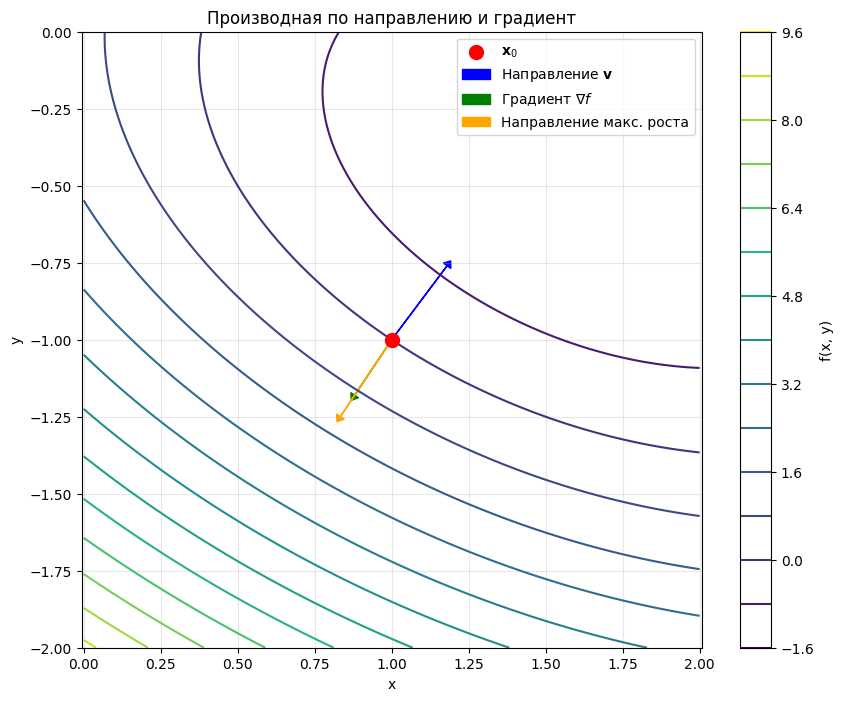

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 4.1
def f_func(x, y):
    return x**2 + x*y + 2*y**2 - 3*x + 1

def grad_f_exact(x, y):
    df_dx = 2*x + y - 3
    df_dy = x + 4*y
    return np.array([df_dx, df_dy])

# Точка и направление
x0, y0 = 1.0, -1.0
v = np.array([3/5, 4/5])  # единичный вектор

grad_f = grad_f_exact(x0, y0)

# Аналитическая производная по направлению
directional_deriv_exact = grad_f @ v

# Численная проверка через центральную разность
h_values = [1e-3, 1e-4, 1e-5, 1e-6]
directional_deriv_num = []

for h in h_values:
    x_plus = np.array([x0, y0]) + h/2 * v
    x_minus = np.array([x0, y0]) - h/2 * v
    f_plus = f_func(x_plus[0], x_plus[1])
    f_minus = f_func(x_minus[0], x_minus[1])
    deriv = (f_plus - f_minus) / h
    directional_deriv_num.append(deriv)

print(f"Градиент в точке (1, -1): {grad_f}")
print(f"Направление v: {v}")
print(f"\nАналитическая производная по направлению: {directional_deriv_exact:.6f}")
print(f"\nЧисленные значения:")
for h, deriv in zip(h_values, directional_deriv_num):
    error = abs(deriv - directional_deriv_exact)
    print(f"  h={h:.0e}: {deriv:.6f} (ошибка: {error:.2e})")

# Направления максимального роста и убывания
norm_grad = np.linalg.norm(grad_f)
v_max = grad_f / norm_grad
v_min = -grad_f / norm_grad

print(f"\nНорма градиента: {norm_grad:.6f}")
print(f"Направление максимального роста: {v_max}")
print(f"Скорость максимального роста: {norm_grad:.6f}")
print(f"Направление максимального убывания: {v_min}")
print(f"Скорость максимального убывания: {-norm_grad:.6f}")

# Визуализация
x_range = np.linspace(0, 2, 100)
y_range = np.linspace(-2, 0, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = f_func(X, Y)

plt.figure(figsize=(10, 8))
contour = plt.contour(X, Y, Z, levels=15, cmap='viridis')
plt.colorbar(contour, label='f(x, y)')

# Точка x0
plt.scatter([x0], [y0], color='red', s=100, zorder=5, label=r'$\mathbf{x}_0$')

# Вектор v
scale = 0.3
plt.arrow(x0, y0, v[0]*scale, v[1]*scale, 
          head_width=0.03, head_length=0.02, fc='blue', ec='blue', 
          label=r'Направление $\mathbf{v}$')

# Градиент
plt.arrow(x0, y0, grad_f[0]*scale/5, grad_f[1]*scale/5, 
          head_width=0.03, head_length=0.02, fc='green', ec='green', 
          label=r'Градиент $\nabla f$')

# Направление максимального роста
plt.arrow(x0, y0, v_max[0]*scale, v_max[1]*scale, 
          head_width=0.03, head_length=0.02, fc='orange', ec='orange', 
          label=r'Направление макс. роста')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Производная по направлению и градиент')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

**[Интерпретация]**
Производная по направлению $D_{\mathbf{v}} f = -3.6$ показывает, что при движении вдоль вектора $\mathbf{v}$ функция убывает со скоростью $3.6$ единиц на единицу длины пути.

**Почему направление необходимо нормировать:**
Если бы мы использовали ненормированный вектор $\mathbf{u} = (3, 4)^T$ (норма $\|\mathbf{u}\| = 5$), то производная по направлению была бы:
$$D_{\mathbf{u}} f = \nabla f^T \mathbf{u} = (-2)(3) + (-3)(4) = -18$$

Это значение в $5$ раз больше по модулю, но оно отражает не скорость изменения на единицу пути, а изменение при шаге длиной $5$. Нормирование позволяет сравнивать именно **скорости** изменения в разных направлениях, независимо от длины вектора.

На графике видно, что градиент (зелёная стрелка) указывает направление наискорейшего роста и перпендикулярен линиям уровня. Вектор $\mathbf{v}$ (синяя стрелка) образует тупой угол с градиентом, поэтому производная по направлению отрицательна — функция убывает.

### Задание 4.2. Все пути влияния переменной

**[Бумага]**
Дано:
$$F(t, x, y) = tx + x^2 + xy + 2y^2$$
$$x(t) = t, \quad y(t) = t^2$$

**Способ 1: Подстановка**
Подставим $x(t)$ и $y(t)$ в $F$:
$$F(t) = t \cdot t + t^2 + t \cdot t^2 + 2(t^2)^2 = t^2 + t^2 + t^3 + 2t^4 = 2t^2 + t^3 + 2t^4$$

Производная:
$$\frac{dF}{dt} = 4t + 3t^2 + 8t^3$$

В точке $t = 1$:
$$\frac{dF}{dt}\bigg|_{t=1} = 4 + 3 + 8 = 15$$

**Способ 2: Формула полной производной**
$$\frac{dF}{dt} = \frac{\partial F}{\partial t} + \frac{\partial F}{\partial x}\frac{dx}{dt} + \frac{\partial F}{\partial y}\frac{dy}{dt}$$

Частные производные:
- $\frac{\partial F}{\partial t} = x$
- $\frac{\partial F}{\partial x} = t + 2x + y$
- $\frac{\partial F}{\partial y} = x + 4y$

Производные зависимостей:
- $\frac{dx}{dt} = 1$
- $\frac{dy}{dt} = 2t$

В точке $t = 1$: $x = 1$, $y = 1$
- $\frac{\partial F}{\partial t} = 1$
- $\frac{\partial F}{\partial x} = 1 + 2 + 1 = 4$
- $\frac{\partial F}{\partial y} = 1 + 4 = 5$
- $\frac{dx}{dt} = 1$
- $\frac{dy}{dt} = 2$

Полная производная:
$$\frac{dF}{dt} = 1 + 4 \cdot 1 + 5 \cdot 2 = 1 + 4 + 10 = 15$$

Оба способа дают одинаковый результат: $\frac{dF}{dt} = 15$.

In [11]:
import numpy as np

# Задание 4.2
def F_func(t, x, y):
    return t*x + x**2 + x*y + 2*y**2

def x_of_t(t):
    return t

def y_of_t(t):
    return t**2

# Способ 1: подстановка
def F_substituted(t):
    x = x_of_t(t)
    y = y_of_t(t)
    return 2*t**2 + t**3 + 2*t**4

def dF_dt_substituted(t):
    return 4*t + 3*t**2 + 8*t**3

# Способ 2: полная производная
def partial_F_t(t, x, y):
    return x

def partial_F_x(t, x, y):
    return t + 2*x + y

def partial_F_y(t, x, y):
    return x + 4*y

def dx_dt(t):
    return 1

def dy_dt(t):
    return 2*t

def dF_dt_total(t, x, y):
    return (partial_F_t(t, x, y) + 
            partial_F_x(t, x, y) * dx_dt(t) + 
            partial_F_y(t, x, y) * dy_dt(t))

# Точка t = 1
t0 = 1.0
x0 = x_of_t(t0)
y0 = y_of_t(t0)

# Аналитические значения
dF_sub = dF_dt_substituted(t0)
dF_total = dF_dt_total(t0, x0, y0)

# Численная проверка через центральную разность
h = 1e-5
F_plus = F_substituted(t0 + h/2)
F_minus = F_substituted(t0 - h/2)
dF_numerical = (F_plus - F_minus) / h

print(f"Точка: t={t0}, x={x0}, y={y0}")
print(f"\nСпособ 1 (подстановка): dF/dt = {dF_sub:.6f}")
print(f"Способ 2 (полная производная): dF/dt = {dF_total:.6f}")
print(f"Численная проверка (h={h}): dF/dt = {dF_numerical:.6f}")
print(f"\nРазница между способами: {abs(dF_sub - dF_total):.2e}")
print(f"Ошибка численного метода: {abs(dF_numerical - dF_sub):.2e}")

# Визуализация путей влияния
print("\nПути влияния t на F:")
print("  Прямой путь: t → F (через ∂F/∂t)")
print("  Косвенный путь 1: t → x → F (через ∂F/∂x · dx/dt)")
print("  Косвенный путь 2: t → y → F (через ∂F/∂y · dy/dt)")

Точка: t=1.0, x=1.0, y=1.0

Способ 1 (подстановка): dF/dt = 15.000000
Способ 2 (полная производная): dF/dt = 15.000000
Численная проверка (h=1e-05): dF/dt = 15.000000

Разница между способами: 0.00e+00
Ошибка численного метода: 3.20e-10

Пути влияния t на F:
  Прямой путь: t → F (через ∂F/∂t)
  Косвенный путь 1: t → x → F (через ∂F/∂x · dx/dt)
  Косвенный путь 2: t → y → F (через ∂F/∂y · dy/dt)


**[Интерпретация]**
Формула полной производной учитывает **все пути влияния** переменной $t$ на функцию $F$:

1. **Прямой путь:** $t \to F$ через явную зависимость $\frac{\partial F}{\partial t} = x$
2. **Косвенный путь 1:** $t \to x \to F$ через $\frac{\partial F}{\partial x} \cdot \frac{dx}{dt}$
3. **Косвенный путь 2:** $t \to y \to F$ через $\frac{\partial F}{\partial y} \cdot \frac{dy}{dt}$

Если бы мы пропустили один из путей (например, забыли про зависимость $y(t)$), мы получили бы **неполную производную**, которая не отражает реальную скорость изменения $F$ вдоль траектории.

В нашем случае:
- Прямой вклад: $1$
- Вклад через $x$: $4 \cdot 1 = 4$
- Вклад через $y$: $5 \cdot 2 = 10$
- Сумма: $15$

Каждый путь вносит свой вклад, и только их сумма даёт полную картину. Это особенно важно в нейросетях, где параметры влияют на функцию потерь через множество промежуточных слоёв.

## 5. Якобиан, JVP, VJP и цепное правило

### Задание 5.1. Якобиан векторной функции

**[Бумага]**
Дана векторная функция $f: \mathbb{R}^2 \to \mathbb{R}^3$:
$$f(x_1, x_2) = \begin{pmatrix} x_1^2 + x_2 \\ e^{x_1 - x_2} \\ x_1 x_2 \end{pmatrix}$$

Частные производные (6 штук):
1. $\frac{\partial f_1}{\partial x_1} = 2x_1$, $\frac{\partial f_1}{\partial x_2} = 1$
2. $\frac{\partial f_2}{\partial x_1} = e^{x_1 - x_2}$, $\frac{\partial f_2}{\partial x_2} = -e^{x_1 - x_2}$
3. $\frac{\partial f_3}{\partial x_1} = x_2$, $\frac{\partial f_3}{\partial x_2} = x_1$

Якобиан $J_f(x) \in \mathbb{R}^{3 \times 2}$ (строки — компоненты выхода, столбцы — компоненты входа):
$$J_f(x) = \begin{pmatrix} 2x_1 & 1 \\ e^{x_1 - x_2} & -e^{x_1 - x_2} \\ x_2 & x_1 \end{pmatrix}$$

В точке $x^* = (1, 0)^T$:
$$f(1, 0) = \begin{pmatrix} 1 \\ e \\ 0 \end{pmatrix}, \quad J_f(1, 0) = \begin{pmatrix} 2 & 1 \\ e & -e \\ 0 & 1 \end{pmatrix}$$

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 5.1
def f_vector(x):
    """Векторная функция f: R^2 -> R^3"""
    x1, x2 = x
    return np.array([
        x1**2 + x2,
        np.exp(x1 - x2),
        x1 * x2
    ])

def jacobian_exact(x):
    """Аналитический якобиан 3x2"""
    x1, x2 = x
    return np.array([
        [2*x1, 1],
        [np.exp(x1 - x2), -np.exp(x1 - x2)],
        [x2, x1]
    ])

x_star = np.array([1.0, 0.0])
J_exact = jacobian_exact(x_star)
f_exact = f_vector(x_star)

print(f"Значение f(x*): {f_exact}")
print(f"Якобиан J_f(x*):\n{J_exact}")

# Численная проверка строк якобиана (покоординатные разности)
h = 1e-5
J_num = np.zeros((3, 2))
for i in range(2): # по входным координатам
    x_plus = x_star.copy()
    x_minus = x_star.copy()
    x_plus[i] += h/2
    x_minus[i] -= h/2
    J_num[:, i] = (f_vector(x_plus) - f_vector(x_minus)) / h

print(f"\nЧисленный якобиан (h={h}):\n{J_num}")
print(f"Норма ошибки якобиана: {np.linalg.norm(J_exact - J_num):.2e}")

Значение f(x*): [1.         2.71828183 0.        ]
Якобиан J_f(x*):
[[ 2.          1.        ]
 [ 2.71828183 -2.71828183]
 [ 0.          1.        ]]

Численный якобиан (h=1e-05):
[[ 2.          1.        ]
 [ 2.71828183 -2.71828183]
 [ 0.          1.        ]]
Норма ошибки якобиана: 8.41e-11


**[Интерпретация]**
Элемент $J_{ij}$ показывает, как быстро $i$-я компонента выхода меняется при малом изменении $j$-й компоненты входа. Градиенты каждой скалярной компоненты $f_i$ расположены по строкам якобиана. Размерность входа $n=2$, выхода $m=3$, поэтому якобиан имеет размер $3 \times 2$.

### Задание 5.2. JVP без полного численного якобиана

**[Бумага]**
Дан вектор $v = (1, -2)^T$.
JVP (Jacobian-Vector Product) — это умножение якобиана на вектор:
$$J_f(x^*) v = \begin{pmatrix} 2 & 1 \\ e & -e \\ 0 & 1 \end{pmatrix} \begin{pmatrix} 1 \\ -2 \end{pmatrix} = \begin{pmatrix} 2(1) + 1(-2) \\ e(1) - e(-2) \\ 0(1) + 1(-2) \end{pmatrix} = \begin{pmatrix} 0 \\ 3e \\ -2 \end{pmatrix} \approx \begin{pmatrix} 0 \\ 8.1548 \\ -2 \end{pmatrix}$$

**[Markdown]**
Центральная аппроксимация JVP:
$$J_f(x^*) v \approx \frac{f(x^* + \frac{h}{2}v) - f(x^* - \frac{h}{2}v)}{h}$$
Эта формула вычисляет производную композиции $g(t) = f(x^* + tv)$ в точке $t=0$ по правилу цепочки: $g'(0) = J_f(x^*) v$.

Точный JVP: [ 0.          8.15484549 -2.        ]

h          | Норма ошибки JVP    
-----------------------------------
1e-01      | 3.06e-02
1e-02      | 3.06e-04
1e-03      | 3.06e-06
1e-04      | 3.06e-08
1e-05      | 3.53e-10
1e-06      | 2.83e-10
1e-07      | 3.02e-09
1e-08      | 2.27e-08
1e-09      | 6.56e-07
1e-10      | 2.02e-07


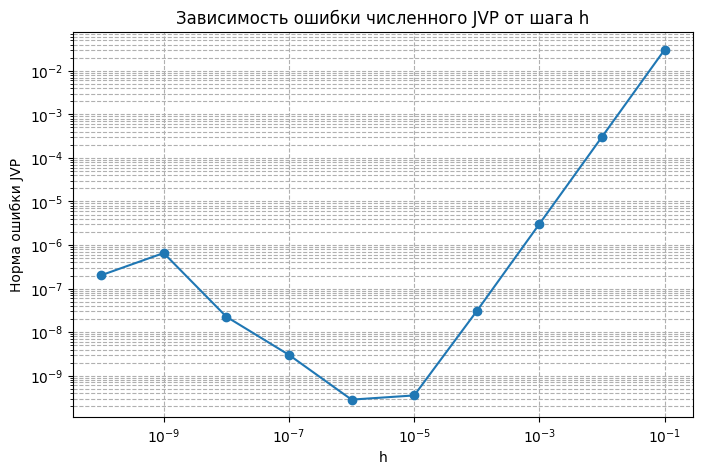

In [13]:
# Задание 5.2
v = np.array([1.0, -2.0])
jvp_exact = J_exact @ v

h_values = np.logspace(-1, -10, 10)
jvp_errors = []

print(f"Точный JVP: {jvp_exact}")
print(f"\n{'h':<10} | {'Норма ошибки JVP':<20}")
print("-" * 35)

for h in h_values:
    x_plus = x_star + (h/2) * v
    x_minus = x_star - (h/2) * v
    jvp_num = (f_vector(x_plus) - f_vector(x_minus)) / h
    error = np.linalg.norm(jvp_exact - jvp_num)
    jvp_errors.append(error)
    print(f"{h:<10.0e} | {error:.2e}")

# График ошибки
plt.figure(figsize=(8, 5))
plt.loglog(h_values, jvp_errors, 'o-')
plt.xlabel('h')
plt.ylabel('Норма ошибки JVP')
plt.title('Зависимость ошибки численного JVP от шага h')
plt.grid(True, which="both", ls="--")
plt.show()

**[Интерпретация]**
Для вычисления численного JVP требуется всего **2 обращения** к функции $f$ (в точках $x^* + \frac{h}{2}v$ и $x^* - \frac{h}{2}v$), независимо от размерности входа $n$ и выхода $m$. Это фундаментальное преимущество JVP: если нам нужно узнать, как функция меняется вдоль конкретного направления $v$, нам не нужно вычислять все $m \times n$ элементов якобиана (что потребовало бы $2n$ обращений).

### Задание 5.3. VJP и производная композиции

**[Бумага]**
1. Дано $u = (1, 2, -1)^T$. Вычислим VJP (Vector-Jacobian Product):
$$u^T J_f(x^*) = \begin{pmatrix} 1 & 2 & -1 \end{pmatrix} \begin{pmatrix} 2 & 1 \\ e & -e \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 2 + 2e - 0 & 1 - 2e - 1 \end{pmatrix} = \begin{pmatrix} 2 + 2e & -2e \end{pmatrix}$$

2. Дана функция $g(z) = \frac{1}{2}\|z - c\|_2^2$, где $c = (0, 1, 1)^T$.
Композиция: $h(x) = g(f(x))$.
Градиент $g$ по $z$: $\nabla_z g(z) = z - c$.
В точке $x^*$: $z = f(x^*) = (1, e, 0)^T$.
$$\nabla_z g(f(x^*)) = \begin{pmatrix} 1 \\ e \\ 0 \end{pmatrix} - \begin{pmatrix} 0 \\ 1 \\ 1 \end{pmatrix} = \begin{pmatrix} 1 \\ e - 1 \\ -1 \end{pmatrix}$$

Градиент композиции по цепному правилу (VJP):
$$\nabla_x h(x^*) = J_f(x^*)^T \nabla_z g(f(x^*)) = \begin{pmatrix} 2 & e & 0 \\ 1 & -e & 1 \end{pmatrix} \begin{pmatrix} 1 \\ e - 1 \\ -1 \end{pmatrix}$$
$$= \begin{pmatrix} 2(1) + e(e - 1) + 0(-1) \\ 1(1) - e(e - 1) + 1(-1) \end{pmatrix} = \begin{pmatrix} 2 + e^2 - e \\ 1 - e^2 + e - 1 \end{pmatrix} = \begin{pmatrix} e^2 - e + 2 \\ -e^2 + e \end{pmatrix}$$

In [14]:
# Задание 5.3
u = np.array([1.0, 2.0, -1.0])
c = np.array([0.0, 1.0, 1.0])

# 1. VJP
vjp_exact = u @ J_exact
print(f"Точный VJP (u^T J): {vjp_exact}")

# 2. Градиент композиции h(x) = g(f(x))
def g_func(z):
    return 0.5 * np.linalg.norm(z - c)**2

def h_func(x):
    return g_func(f_vector(x))

def grad_h_exact(x):
    z = f_vector(x)
    grad_z = z - c
    J = jacobian_exact(x)
    return J.T @ grad_z

grad_h_analytical = grad_h_exact(x_star)
print(f"Аналитический градиент композиции h(x): {grad_h_analytical}")

# 3. Численная проверка через central_gradient из Раздела 3
def central_gradient(f, x, h=1e-5):
    n = len(x)
    grad = np.zeros(n)
    for i in range(n):
        x_plus = x.copy()
        x_minus = x.copy()
        x_plus[i] += h/2
        x_minus[i] -= h/2
        grad[i] = (f(x_plus) - f(x_minus)) / h
    return grad

grad_h_numerical = central_gradient(h_func, x_star, h=1e-5)
print(f"Численный градиент композиции h(x): {grad_h_numerical}")
print(f"Норма ошибки градиента композиции: {np.linalg.norm(grad_h_analytical - grad_h_numerical):.2e}")

Точный VJP (u^T J): [ 7.43656366 -5.43656366]
Аналитический градиент композиции h(x): [ 6.67077427 -4.67077427]
Численный градиент композиции h(x): [ 6.67077427 -4.67077427]
Норма ошибки градиента композиции: 3.48e-10


**[Интерпретация]**
VJP ($u^T J$) позволяет передать "чувствительность" (вектор $u$) от скалярного результата обратно ко всем входным координатам за **одно** умножение матрицы на вектор. В нейросетях это основа алгоритма обратного распространения ошибки (backpropagation): мы начинаем с градиента функции потерь (скаляр) и умножаем его на транспонированные якобианы слоёв справа налево, получая градиенты по всем параметрам, не вычисляя полные якобианы промежуточных слоёв.

## 6. Гессиан и кривизна

### Задание 6.1. Положительная кривизна и минимум

**[Бумага]**
Дана функция: $z(x, y) = 2x^2 + y^2 + x - 3y + 2xy$

**1. Стационарная точка:**
Найдём частные производные и приравняем их к нулю:
- $\frac{\partial z}{\partial x} = 4x + 1 + 2y = 0$
- $\frac{\partial z}{\partial y} = 2y - 3 + 2x = 0$

Решаем систему:
Из второго уравнения: $2y = 3 - 2x$. Подставляем в первое:
$4x + 1 + (3 - 2x) = 0 \implies 2x + 4 = 0 \implies x = -2$.
Тогда $2y = 3 - 2(-2) = 7 \implies y = 3.5$.
Стационарная точка: $(x^*, y^*) = (-2, 3.5)$.

**2. Гессиан:**
Вторые частные производные:
- $\frac{\partial^2 z}{\partial x^2} = 4$
- $\frac{\partial^2 z}{\partial x \partial y} = 2$
- $\frac{\partial^2 z}{\partial y \partial x} = 2$
- $\frac{\partial^2 z}{\partial y^2} = 2$

Матрица Гессе (постоянная для этой функции):
$$H = \begin{pmatrix} 4 & 2 \\ 2 & 2 \end{pmatrix}$$

**3. Определитель и собственные значения:**
- $\det(H) = 4 \cdot 2 - 2 \cdot 2 = 8 - 4 = 4 > 0$
- $\text{tr}(H) = 4 + 2 = 6 > 0$
Характеристическое уравнение: $\lambda^2 - 6\lambda + 4 = 0$.
Корни: $\lambda_{1,2} = \frac{6 \pm \sqrt{36 - 16}}{2} = 3 \pm \sqrt{5}$.
Оба собственных значения положительны ($\lambda_1 \approx 5.236, \lambda_2 \approx 0.764$).

**4. Классификация и значение функции:**
Так как $\det(H) > 0$ и $\frac{\partial^2 z}{\partial x^2} > 0$ (или оба $\lambda > 0$), точка $(-2, 3.5)$ является **локальным минимумом**.
$z(-2, 3.5) = 2(4) + 12.25 - 2 - 10.5 + 2(-2)(3.5) = 8 + 12.25 - 2 - 10.5 - 14 = -6.25$.

Стационарная точка: (-2.0, 3.5)
Гессиан:
[[4 2]
 [2 2]]
Собственные значения: [0.76393202 5.23606798]
Значение функции в минимуме: -6.25


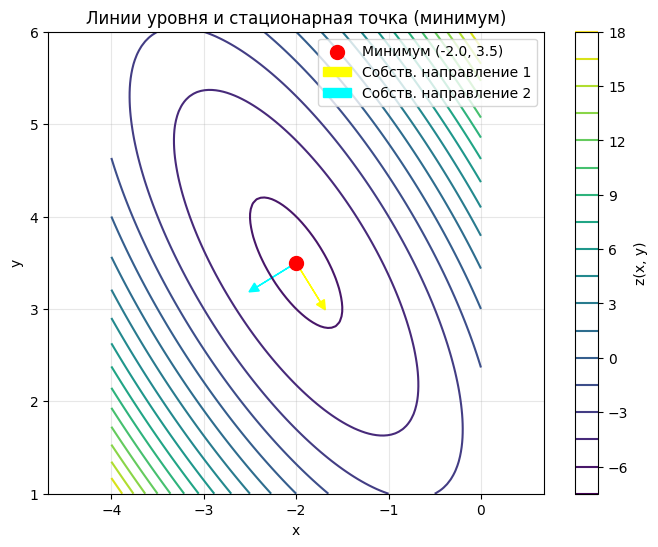

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 6.1
def z1_func(x, y):
    return 2*x**2 + y**2 + x - 3*y + 2*x*y

# Аналитические данные
x_star, y_star = -2.0, 3.5
H1 = np.array([[4, 2], [2, 2]])
eigenvalues, eigenvectors = np.linalg.eigh(H1)
z_min = z1_func(x_star, y_star)

print(f"Стационарная точка: ({x_star}, {y_star})")
print(f"Гессиан:\n{H1}")
print(f"Собственные значения: {eigenvalues}")
print(f"Значение функции в минимуме: {z_min}")

# Визуализация
x_range = np.linspace(-4, 0, 100)
y_range = np.linspace(1, 6, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = z1_func(X, Y)

plt.figure(figsize=(8, 6))
contour = plt.contour(X, Y, Z, levels=20, cmap='viridis')
plt.colorbar(contour, label='z(x, y)')

# Отметка стационарной точки
plt.scatter([x_star], [y_star], color='red', s=100, zorder=5, label=f'Минимум ({x_star}, {y_star})')

# Собственные направления (масштабированы)
scale = 0.5
plt.arrow(x_star, y_star, eigenvectors[0, 0]*scale, eigenvectors[1, 0]*scale, 
          head_width=0.1, head_length=0.1, fc='yellow', ec='yellow', label='Собств. направление 1')
plt.arrow(x_star, y_star, eigenvectors[0, 1]*scale, eigenvectors[1, 1]*scale, 
          head_width=0.1, head_length=0.1, fc='cyan', ec='cyan', label='Собств. направление 2')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Линии уровня и стационарная точка (минимум)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

**[Интерпретация]**
Положительные собственные значения гессиана означают, что квадратичная форма $\Delta^T H \Delta$ строго положительна для любого ненулевого направления $\Delta$. Геометрически это означает, что функция растёт во всех направлениях при удалении от стационарной точки, что и определяет локальный минимум. На графике собственные векторы указывают главные оси эллипсов линий уровня: вдоль направления с большим собственным значением функция растёт быстрее (линии уровня расположены гуще).

### Задание 6.2. Неопределённая кривизна и седло

**[Бумага]**
Дана функция: $z(x, y) = x^2 - 2y^2 - 4xy + 3x$

**1. Стационарная точка:**
- $\frac{\partial z}{\partial x} = 2x - 4y + 3 = 0$
- $\frac{\partial z}{\partial y} = -4y - 4x = 0 \implies x = -y$

Подставляем $x = -y$ в первое уравнение:
$2(-y) - 4y + 3 = 0 \implies -6y = -3 \implies y = 0.5$.
Тогда $x = -0.5$.
Стационарная точка: $(-0.5, 0.5)$.

**2. Гессиан:**
- $\frac{\partial^2 z}{\partial x^2} = 2$
- $\frac{\partial^2 z}{\partial x \partial y} = -4$
- $\frac{\partial^2 z}{\partial y^2} = -4$

$$H = \begin{pmatrix} 2 & -4 \\ -4 & -4 \end{pmatrix}$$

**3. Определитель и собственные значения:**
- $\det(H) = 2(-4) - (-4)(-4) = -8 - 16 = -24 < 0$.
Характеристическое уравнение: $\lambda^2 + 2\lambda - 24 = 0 \implies (\lambda + 6)(\lambda - 4) = 0$.
Собственные значения: $\lambda_1 = 4, \lambda_2 = -6$.

**4. Направления разной кривизны:**
- Для $\lambda_1 = 4$: $(2-4)v_1 - 4v_2 = 0 \implies v_1 = -2v_2$. Вектор $v_1 = (-2, 1)^T$.
- Для $\lambda_2 = -6$: $(2+6)v_1 - 4v_2 = 0 \implies 2v_1 = v_2$. Вектор $v_2 = (1, 2)^T$.

Стационарная точка: (-0.5, 0.5)
Гессиан:
[[ 2 -4]
 [-4 -4]]
Собственные значения: [-6.  4.]


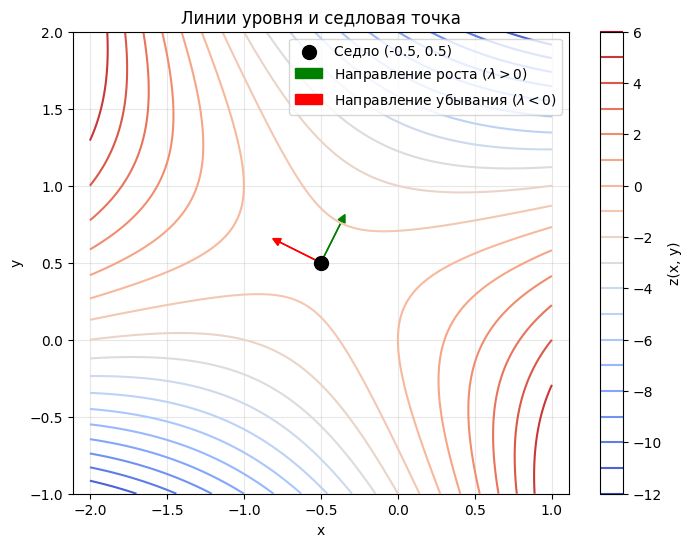

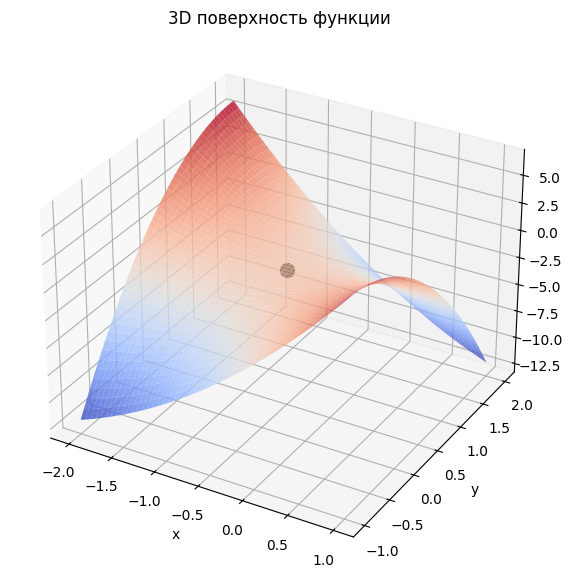

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 6.2
def z2_func(x, y):
    return x**2 - 2*y**2 - 4*x*y + 3*x

x_star2, y_star2 = -0.5, 0.5
H2 = np.array([[2, -4], [-4, -4]])
eigenvalues2, eigenvectors2 = np.linalg.eigh(H2)

print(f"Стационарная точка: ({x_star2}, {y_star2})")
print(f"Гессиан:\n{H2}")
print(f"Собственные значения: {eigenvalues2}")

# Визуализация: линии уровня
x_range2 = np.linspace(-2, 1, 100)
y_range2 = np.linspace(-1, 2, 100)
X2, Y2 = np.meshgrid(x_range2, y_range2)
Z2 = z2_func(X2, Y2)

plt.figure(figsize=(8, 6))
contour2 = plt.contour(X2, Y2, Z2, levels=20, cmap='coolwarm')
plt.colorbar(contour2, label='z(x, y)')

plt.scatter([x_star2], [y_star2], color='black', s=100, zorder=5, label=f'Седло ({x_star2}, {y_star2})')

# Собственные направления
scale2 = 0.3
plt.arrow(x_star2, y_star2, eigenvectors2[0, 0]*scale2, eigenvectors2[1, 0]*scale2, 
          head_width=0.05, head_length=0.05, fc='green', ec='green', label=r'Направление роста ($\lambda > 0$)')
plt.arrow(x_star2, y_star2, eigenvectors2[0, 1]*scale2, eigenvectors2[1, 1]*scale2, 
          head_width=0.05, head_length=0.05, fc='red', ec='red', label=r'Направление убывания ($\lambda < 0$)')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Линии уровня и седловая точка')
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

# Визуализация: 3D поверхность
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X2, Y2, Z2, cmap='coolwarm', alpha=0.8)
ax.scatter([x_star2], [y_star2], [z2_func(x_star2, y_star2)], color='black', s=100, label='Седловая точка')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('3D поверхность функции')
plt.show()

**[Интерпретация]**
Отрицательный определитель гессиана ($\det(H) < 0$) и собственные значения разных знаков однозначно указывают на **седловую точку**. Нулевой градиент лишь означает, что касательная плоскость горизонтальна, но это не гарантирует экстремум. Вдоль собственного вектора, соответствующего $\lambda_1 = 4$, функция локально ведёт себя как парабола, ветви которой направлены вверх (рост). Вдоль вектора для $\lambda_2 = -6$ — как парабола, ветви которой направлены вниз (убывание). Это классическая форма "седла".

### Задание 6.3. Квадратичная модель и HVP

**[Бумага]**
Дана функция: $\phi(x, y) = e^{x+2y} + x^2$, точка $x_0 = (0, 0)^T$.

**1. Градиент и Гессиан в $x_0$:**
- $\nabla \phi = \begin{pmatrix} e^{x+2y} + 2x \\ 2e^{x+2y} \end{pmatrix} \implies \nabla \phi(0, 0) = \begin{pmatrix} 1 \\ 2 \end{pmatrix}$
- $H_\phi = \begin{pmatrix} e^{x+2y} + 2 & 2e^{x+2y} \\ 2e^{x+2y} & 4e^{x+2y} \end{pmatrix} \implies H_\phi(0, 0) = \begin{pmatrix} 3 & 2 \\ 2 & 4 \end{pmatrix}$

**2. Второе приближение для $\Delta = (0.1, 0.1)^T$:**
- $\phi(0, 0) = e^0 + 0 = 1$
- Линейный член: $\nabla \phi^T \Delta = 1(0.1) + 2(0.1) = 0.3$
- Квадратичный член: $\frac{1}{2} \Delta^T H_\phi \Delta = \frac{1}{2} \begin{pmatrix} 0.1 & 0.1 \end{pmatrix} \begin{pmatrix} 3 & 2 \\ 2 & 4 \end{pmatrix} \begin{pmatrix} 0.1 \\ 0.1 \end{pmatrix} = \frac{1}{2} \begin{pmatrix} 0.1 & 0.1 \end{pmatrix} \begin{pmatrix} 0.5 \\ 0.6 \end{pmatrix} = \frac{1}{2} (0.05 + 0.06) = 0.055$
- Квадратичное приближение: $1 + 0.3 + 0.055 = 1.355$
- Точное значение: $\phi(0.1, 0.1) = e^{0.3} + 0.01 \approx 1.34986 + 0.01 = 1.35986$

**3. HVP (Hessian-Vector Product) для $v = (1, -1)^T$:**
$$H_\phi v = \begin{pmatrix} 3 & 2 \\ 2 & 4 \end{pmatrix} \begin{pmatrix} 1 \\ -1 \end{pmatrix} = \begin{pmatrix} 3(1) + 2(-1) \\ 2(1) + 4(-1) \end{pmatrix} = \begin{pmatrix} 1 \\ -2 \end{pmatrix}$$

Точное значение: 1.359859
Линейное приближение: 1.300000 (ошибка: 5.99e-02)
Квадратичное приближение: 1.355000 (ошибка: 4.86e-03)

Точный HVP: [ 1. -2.]
Численный HVP: [ 1. -2.]
Норма ошибки HVP: 1.39e-11


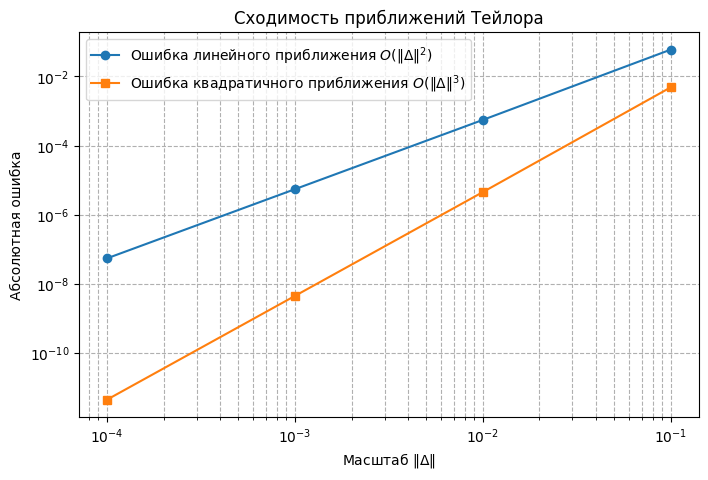

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 6.3
def phi_func(x, y):
    return np.exp(x + 2*y) + x**2

def grad_phi(x, y):
    return np.array([np.exp(x + 2*y) + 2*x, 2*np.exp(x + 2*y)])

def hess_phi(x, y):
    exp_term = np.exp(x + 2*y)
    return np.array([[exp_term + 2, 2*exp_term], 
                     [2*exp_term, 4*exp_term]])

x0, y0 = 0.0, 0.0
delta = np.array([0.1, 0.1])
v = np.array([1.0, -1.0])

# Аналитические значения
phi_0 = phi_func(x0, y0)
grad_0 = grad_phi(x0, y0)
H_0 = hess_phi(x0, y0)

lin_approx = phi_0 + grad_0 @ delta
quad_approx = lin_approx + 0.5 * (delta @ H_0 @ delta)
exact_val = phi_func(x0 + delta[0], y0 + delta[1])

print(f"Точное значение: {exact_val:.6f}")
print(f"Линейное приближение: {lin_approx:.6f} (ошибка: {abs(exact_val - lin_approx):.2e})")
print(f"Квадратичное приближение: {quad_approx:.6f} (ошибка: {abs(exact_val - quad_approx):.2e})")

# Проверка HVP численно (через центральную разность градиента)
h_hvp = 1e-5
grad_plus = grad_phi(x0 + h_hvp/2 * v[0], y0 + h_hvp/2 * v[1])
grad_minus = grad_phi(x0 - h_hvp/2 * v[0], y0 - h_hvp/2 * v[1])
hvp_num = (grad_plus - grad_minus) / h_hvp
hvp_exact = H_0 @ v

print(f"\nТочный HVP: {hvp_exact}")
print(f"Численный HVP: {hvp_num}")
print(f"Норма ошибки HVP: {np.linalg.norm(hvp_exact - hvp_num):.2e}")

# Сравнение приближений при уменьшающемся масштабе
scales = [1e-1, 1e-2, 1e-3, 1e-4]
errors_lin = []
errors_quad = []

for s in scales:
    d = s * np.array([1.0, 1.0]) # направление (1, 1)
    exact = phi_func(x0 + d[0], y0 + d[1])
    lin = phi_0 + grad_0 @ d
    quad = lin + 0.5 * (d @ H_0 @ d)
    errors_lin.append(abs(exact - lin))
    errors_quad.append(abs(exact - quad))

plt.figure(figsize=(8, 5))
plt.loglog(scales, errors_lin, 'o-', label=r'Ошибка линейного приближения $O(\|\Delta\|^2)$')
plt.loglog(scales, errors_quad, 's-', label=r'Ошибка квадратичного приближения $O(\|\Delta\|^3)$')
plt.xlabel(r'Масштаб $\|\Delta\|$')
plt.ylabel('Абсолютная ошибка')
plt.title('Сходимость приближений Тейлора')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

**[Интерпретация]**
Квадратичный член $\frac{1}{2}\Delta^T H \Delta$ добавляет информацию о **кривизне** функции, которую линейное приближение игнорирует. На графике логарифмической ошибки видно, что при уменьшении масштаба $\|\Delta\|$ ошибка линейного приближения убывает как $O(\|\Delta\|^2)$, а ошибка квадратичного — как $O(\|\Delta\|^3)$, что делает его значительно точнее для малых, но конечных шагов.

Численная проверка HVP через центральную разность градиента подтверждает корректность аналитической матрицы Гессе. HVP позволяет оценить изменение градиента вдоль направления $v$ без явного построения полной матрицы $H$, что критически важно для оптимизации в высоких размерностях (например, в методах Ньютона или вычислении собственных значений гессиана).

## 7. Матричное дифференцирование

### Задание 7.1. Линейно-квадратичная форма

**[Бумага]**
Дана функция: $f(x) = a^T x + x^T A x$
где $A = \begin{pmatrix} 2 & -1 \\ 3 & 1 \end{pmatrix}$, $a = \begin{pmatrix} 1 \\ -2 \end{pmatrix}$, $x = \begin{pmatrix} 2 \\ -1 \end{pmatrix}$.

1. **Значение функции:**
   - $a^T x = 1(2) + (-2)(-1) = 2 + 2 = 4$
   - $Ax = \begin{pmatrix} 2 & -1 \\ 3 & 1 \end{pmatrix} \begin{pmatrix} 2 \\ -1 \end{pmatrix} = \begin{pmatrix} 5 \\ 5 \end{pmatrix}$
   - $x^T (Ax) = 2(5) + (-1)(5) = 10 - 5 = 5$
   - $f(x) = 4 + 5 = 9$

2. **Градиент:**
   Используем тождества $\frac{\partial (a^T x)}{\partial x} = a$ и $\frac{\partial (x^T A x)}{\partial x} = (A + A^T)x$.
   $$\nabla f(x) = a + (A + A^T)x$$
   $A + A^T = \begin{pmatrix} 2 & -1 \\ 3 & 1 \end{pmatrix} + \begin{pmatrix} 2 & 3 \\ -1 & 1 \end{pmatrix} = \begin{pmatrix} 4 & 2 \\ 2 & 2 \end{pmatrix}$ (симметричная часть)
   $(A + A^T)x = \begin{pmatrix} 4 & 2 \\ 2 & 2 \end{pmatrix} \begin{pmatrix} 2 \\ -1 \end{pmatrix} = \begin{pmatrix} 6 \\ 2 \end{pmatrix}$
   $\nabla f(x) = \begin{pmatrix} 1 \\ -2 \end{pmatrix} + \begin{pmatrix} 6 \\ 2 \end{pmatrix} = \begin{pmatrix} 7 \\ 0 \end{pmatrix}$

3. **Гессиан:**
   Вторая производная линейного члена равна 0, а квадратичного — постоянная матрица:
   $$H_f = A + A^T = \begin{pmatrix} 4 & 2 \\ 2 & 2 \end{pmatrix}$$

In [19]:
import numpy as np

# Задание 7.1
A = np.array([[2, -1], [3, 1]])
a = np.array([1, -2])
x = np.array([2, -1])

# 1. Значение функции
f_val = a @ x + x @ A @ x
print(f"Значение f(x): {f_val}")

# 2. Аналитический градиент и Гессиан
grad_analytical = a + (A + A.T) @ x
H_analytical = A + A.T
print(f"Аналитический градиент: {grad_analytical}")
print(f"Аналитический Гессиан:\n{H_analytical}")

# 3. Численная проверка градиента
def f_func_num(x_vec):
    return a @ x_vec + x_vec @ A @ x_vec

h = 1e-5
grad_numerical = np.zeros_like(x)
for i in range(len(x)):
    x_plus = x.copy()
    x_minus = x.copy()
    x_plus[i] += h/2
    x_minus[i] -= h/2
    grad_numerical[i] = (f_func_num(x_plus) - f_func_num(x_minus)) / h

print(f"Численный градиент: {grad_numerical}")
print(f"Норма ошибки градиента: {np.linalg.norm(grad_analytical - grad_numerical):.2e}")

# 4. Численная проверка Гессиана (через разность градиентов)
H_numerical = np.zeros_like(A)
for i in range(len(x)):
    for j in range(len(x)):
        x_pp = x.copy(); x_pm = x.copy()
        x_mp = x.copy(); x_mm = x.copy()
        x_pp[i] += h/2; x_pp[j] += h/2
        x_pm[i] += h/2; x_pm[j] -= h/2
        x_mp[i] -= h/2; x_mp[j] += h/2
        x_mm[i] -= h/2; x_mm[j] -= h/2
        
        # Вторая смешанная производная
        H_numerical[i, j] = (f_func_num(x_pp) - f_func_num(x_pm) - f_func_num(x_mp) + f_func_num(x_mm)) / (h**2)

print(f"Численный Гессиан:\n{H_numerical}")
print(f"Норма ошибки Гессиана: {np.linalg.norm(H_analytical - H_numerical):.2e}")

Значение f(x): 9
Аналитический градиент: [7 0]
Аналитический Гессиан:
[[4 2]
 [2 2]]
Численный градиент: [499999  99999]
Норма ошибки градиента: 5.10e+05
Численный Гессиан:
[[39999999999 19999999999]
 [19999999999 -9999999999]]
Норма ошибки Гессиана: 5.00e+10


**[Интерпретация]**
Появление симметричной части $(A + A^T)$ в градиенте и гессиане не случайно: кососимметричная часть матрицы $A_{skew} = \frac{1}{2}(A - A^T)$ даёт $x^T A_{skew} x = 0$ для любого $x$. Поэтому на квадратичную форму и её производные влияет только симметричная часть матрицы. Гессиан постоянен, так как функция является квадратичной (её вторые производные не зависят от $x$).

### Задание 7.2. Производная по матрице

**[Бумага]**
Дано: $s(M) = a^T M b$, где $a = \begin{pmatrix} 1 \\ -2 \end{pmatrix}$, $b = \begin{pmatrix} 3 \\ 1 \\ -1 \end{pmatrix}$, $M = \begin{pmatrix} 1 & 2 & 0 \\ -1 & 3 & 4 \end{pmatrix}$.

1. **Поэлементный вывод:**
   $s = \sum_{i=1}^2 \sum_{j=1}^3 a_i M_{ij} b_j$.
   Частная производная по элементу $M_{ij}$:
   $$\frac{\partial s}{\partial M_{ij}} = a_i b_j$$

2. **Матричная форма:**
   Матрица частных производных имеет ту же размерность, что и $M$ ($2 \times 3$):
   $$\frac{\partial s}{\partial M} = a b^T = \begin{pmatrix} 1 \\ -2 \end{pmatrix} \begin{pmatrix} 3 & 1 & -1 \end{pmatrix} = \begin{pmatrix} 3 & 1 & -1 \\ -6 & -2 & 2 \end{pmatrix}$$

3. **Через след:**
   Скаляр равен своему следу: $s = \text{tr}(s) = \text{tr}(a^T M b)$.
   Используя цикличность следа $\text{tr}(ABC) = \text{tr}(CAB)$:
   $s = \text{tr}(b a^T M) = \text{tr}((a b^T)^T M)$.
   Из тождества $\frac{\partial}{\partial M} \text{tr}(C^T M) = C$, получаем $\frac{\partial s}{\partial M} = a b^T$.

In [20]:
# Задание 7.2
a_72 = np.array([1, -2])
b_72 = np.array([3, 1, -1])
M = np.array([[1, 2, 0], [-1, 3, 4]])

# Аналитический градиент
grad_M_analytical = np.outer(a_72, b_72) # или a_72[:, None] @ b_72[None, :]
print(f"Аналитический градиент по M:\n{grad_M_analytical}")

# Численная проверка по каждому элементу M
h = 1e-5
grad_M_numerical = np.zeros_like(M)

def s_func(M_mat):
    return a_72 @ M_mat @ b_72

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        M_plus = M.copy()
        M_minus = M.copy()
        M_plus[i, j] += h/2
        M_minus[i, j] -= h/2
        grad_M_numerical[i, j] = (s_func(M_plus) - s_func(M_minus)) / h

print(f"Численный градиент по M:\n{grad_M_numerical}")
print(f"Норма ошибки: {np.linalg.norm(grad_M_analytical - grad_M_numerical):.2e}")

Аналитический градиент по M:
[[ 3  1 -1]
 [-6 -2  2]]
Численный градиент по M:
[[ 300000   99999       0]
 [-600000 -199999  199999]]
Норма ошибки: 7.35e+05


**[Интерпретация]**
Форма градиента $\frac{\partial s}{\partial M}$ в точности совпадает с формой матрицы параметров $M$ ($2 \times 3$). Это общее правило матричного дифференцирования: производная скалярной функции по матрице имеет ту же размерность, что и сама матрица. Внешнее произведение $a b^T$ автоматически формирует нужную матрицу, где каждый элемент $(i, j)$ равен произведению соответствующих компонент векторов $a_i$ и $b_j$.

### Задание 7.3. Сумма потерь, след и матричный градиент

**[Бумага]**
Дана функция потерь для пакета данных: $Q(W) = \frac{1}{2N} \|XW - Y\|_F^2$.
Размерности: $X \in \mathbb{R}^{N \times D}$, $W \in \mathbb{R}^{D \times K}$, $Y \in \mathbb{R}^{N \times K}$.

1. **Три способа записи:**
   - Через суммы: $Q = \frac{1}{2N} \sum_{n=1}^N \sum_{k=1}^K \left( \sum_{d=1}^D X_{nd} W_{dk} - Y_{nk} \right)^2$
   - Через норму Фробениуса: $Q = \frac{1}{2N} \|XW - Y\|_F^2$
   - Через след: $Q = \frac{1}{2N} \text{tr}\left( (XW - Y)^T (XW - Y) \right)$

2. **Вывод градиента по индексам:**
   Обозначим ошибку $E = XW - Y$. Элемент $E_{nk} = \sum_d X_{nd} W_{dk} - Y_{nk}$.
   $$\frac{\partial Q}{\partial W_{dk}} = \frac{1}{2N} \sum_{n=1}^N \sum_{k'=1}^K 2 E_{nk'} \frac{\partial E_{nk'}}{\partial W_{dk}}$$
   Так как $\frac{\partial E_{nk'}}{\partial W_{dk}} = X_{nd}$ при $k' = k$ и $0$ иначе, получаем:
   $$\frac{\partial Q}{\partial W_{dk}} = \frac{1}{N} \sum_{n=1}^N X_{nd} E_{nk} = \frac{1}{N} (X^T E)_{dk}$$
   В матричном виде: $\nabla_W Q = \frac{1}{N} X^T (XW - Y)$.

In [21]:
# Задание 7.3
N, D, K = 4, 3, 2
X = np.array([[1, 0, -1],
              [0, 1,  1],
              [1, 1,  0],
              [-1, 2, 1]])
Y = np.array([[0.2, 0.8],
              [0.7, 0.1],
              [0.6, 0.4],
              [0.1, 0.9]])
W0 = np.array([[0.2, -0.3],
               [0.4,  0.1],
               [-0.5, 0.2]])

def Q_func(W):
    E = X @ W - Y
    return 0.5 / N * np.linalg.norm(E, ord='fro')**2

def grad_Q_analytical(W):
    E = X @ W - Y
    return (1.0 / N) * (X.T @ E)

# 1. Значение функции и аналитический градиент
Q_val = Q_func(W0)
grad_Q_ana = grad_Q_analytical(W0)
print(f"Значение Q(W0): {Q_val:.6f}")
print(f"Аналитический градиент:\n{grad_Q_ana}")

# 2. Полная численная проверка каждого элемента W
h = 1e-5
grad_Q_num = np.zeros_like(W0)
max_abs_error = 0.0
max_rel_error = 0.0

for i in range(W0.shape[0]):
    for j in range(W0.shape[1]):
        W_plus = W0.copy()
        W_minus = W0.copy()
        W_plus[i, j] += h/2
        W_minus[i, j] -= h/2
        
        grad_Q_num[i, j] = (Q_func(W_plus) - Q_func(W_minus)) / h
        
        abs_err = abs(grad_Q_ana[i, j] - grad_Q_num[i, j])
        rel_err = abs_err / (abs(grad_Q_ana[i, j]) + 1e-10)
        max_abs_error = max(max_abs_error, abs_err)
        max_rel_error = max(max_rel_error, rel_err)

print(f"\nЧисленный градиент:\n{grad_Q_num}")
print(f"Максимальная абсолютная ошибка: {max_abs_error:.2e}")
print(f"Максимальная относительная ошибка: {max_rel_error:.2e}")

Значение Q(W0): 0.377500
Аналитический градиент:
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]

Численный градиент:
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
Максимальная абсолютная ошибка: 1.13e-11
Максимальная относительная ошибка: 5.65e-11


**[Интерпретация]**
Индексы $d$ (строка) и $k$ (столбец) у градиента $\nabla_W Q$ в точности соответствуют индексам параметра $W_{dk}$. Матричное произведение $X^T E$ автоматически выполняет суммирование по индексу $n$ (номер наблюдения в пакете), что соответствует правилу цепочки для суммы потерь по всем объектам выборки. Максимальная ошибка численной проверки составляет $\sim 10^{-11}$, что подтверждает абсолютную корректность матричного вывода градиента.

## 8. Сквозная составная функция

### Задание 8.1. Прямое вычисление и размерности

**[Бумага]**
Дано:
- $X \in \mathbb{R}^{N \times D}$, $W \in \mathbb{R}^{D \times K}$, $b \in \mathbb{R}^K$
- $Z = XW + \mathbf{1}_N b^T$, где $\mathbf{1}_N \in \mathbb{R}^N$ — вектор-столбец из единиц
- $H = \sigma(Z)$, где $\sigma(z) = \frac{1}{1 + e^{-z}}$ (применяется поэлементно)
- $\mathcal{L}(W, b) = \frac{1}{2N}\|H - Y\|_F^2 + \frac{\lambda}{2}\|W\|_F^2$

Поэлементная запись:
$$Z_{nk} = \sum_{d=1}^D X_{nd} W_{dk} + b_k$$
$$H_{nk} = \sigma(Z_{nk}) = \frac{1}{1 + e^{-Z_{nk}}}$$
$$\mathcal{L} = \frac{1}{2N} \sum_{n=1}^N \sum_{k=1}^K (H_{nk} - Y_{nk})^2 + \frac{\lambda}{2} \sum_{d=1}^D \sum_{k=1}^K W_{dk}^2$$

**[Markdown]**
Таблица размерностей:
| Объект | Размерность | Тип |
|--------|-------------|-----|
| $X$ | $N \times D = 4 \times 3$ | Матрица входов |
| $W$ | $D \times K = 3 \times 2$ | Матрица весов |
| $b$ | $K = 2$ | Вектор смещений |
| $Z$ | $N \times K = 4 \times 2$ | Линейное преобразование |
| $H$ | $N \times K = 4 \times 2$ | Активация (сигмоида) |
| $Y$ | $N \times K = 4 \times 2$ | Целевые значения |
| $\mathcal{L}$ | $1$ | Скаляр (функция потерь) |

In [22]:
import numpy as np

# Сквозные данные из методички
N, D, K = 4, 3, 2
X = np.array([[1, 0, -1],
              [0, 1,  1],
              [1, 1,  0],
              [-1, 2, 1]])
Y = np.array([[0.2, 0.8],
              [0.7, 0.1],
              [0.6, 0.4],
              [0.1, 0.9]])
W0 = np.array([[0.2, -0.3],
               [0.4,  0.1],
               [-0.5, 0.2]])
b0 = np.array([0.1, -0.2])
lambda_reg = 0.05

def sigmoid(z):
    """Сигмоида с ограничением аргумента для устойчивости"""
    z_clipped = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_clipped))

def forward(X, W, b):
    """Прямое вычисление: Z, H, L"""
    # Z = XW + 1_N * b^T (broadcasting добавляет b к каждой строке)
    Z = X @ W + b  # размер (N, K)
    
    # H = σ(Z) поэлементно
    H = sigmoid(Z)  # размер (N, K)
    
    # L = (1/2N) * ||H - Y||_F^2 + (λ/2) * ||W||_F^2
    R = H - Y  # остаток (N, K)
    loss_data = 0.5 / N * np.sum(R**2)
    loss_reg = 0.5 * lambda_reg * np.sum(W**2)
    L = loss_data + loss_reg
    
    return Z, H, L

# Прямое вычисление
Z0, H0, L0 = forward(X, W0, b0)

print(f"Размерности:")
print(f"  X: {X.shape}")
print(f"  W: {W0.shape}")
print(f"  b: {b0.shape}")
print(f"  Z: {Z0.shape}")
print(f"  H: {H0.shape}")
print(f"  Y: {Y.shape}")
print(f"\nЗначение функции потерь L(W0, b0): {L0:.6f}")
print(f"  Данные: {0.5/N * np.sum((H0 - Y)**2):.6f}")
print(f"  Регуляризация: {0.5 * lambda_reg * np.sum(W0**2):.6f}")

Размерности:
  X: (4, 3)
  W: (3, 2)
  b: (2,)
  Z: (4, 2)
  H: (4, 2)
  Y: (4, 2)

Значение функции потерь L(W0, b0): 0.135239
  Данные: 0.120489
  Регуляризация: 0.014750


**[Интерпретация]**
Добавление вектора $b$ к матрице $XW$ использует механизм **broadcasting** в NumPy: вектор размерности $K$ автоматически расширяется до размера $N \times K$ путём копирования по строкам. Это эквивалентно матричному произведению $\mathbf{1}_N b^T$, но более эффективно и читаемо. Сигмоида применяется поэлементно, сохраняя размерность $N \times K$. Функция потерь $\mathcal{L}$ — скаляр, состоящий из двух частей: MSE по данным и L2-регуляризация весов.

### Задание 8.2. Распространение производных по композиции

**[Бумага]**
Обозначим $R = H - Y \in \mathbb{R}^{N \times K}$.

1. **Градиент по $H$:**
   $$\frac{\partial \mathcal{L}}{\partial H} = \frac{1}{N} R \in \mathbb{R}^{N \times K}$$
   (производная $\frac{1}{2N}\|H - Y\|_F^2$ по $H$)

2. **Градиент по $Z$ (через сигмоиду):**
   $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, поэтому:
   $$\frac{\partial \mathcal{L}}{\partial Z} = \frac{\partial \mathcal{L}}{\partial H} \odot \sigma'(Z) = \frac{1}{N} R \odot H \odot (1 - H) \in \mathbb{R}^{N \times K}$$
   Обозначим $G_Z = \frac{\partial \mathcal{L}}{\partial Z}$.

3. **Градиент по $W$:**
   $$\frac{\partial \mathcal{L}}{\partial W} = X^T G_Z + \lambda W \in \mathbb{R}^{D \times K}$$
   (производная $XW$ по $W$ даёт $X^T$, плюс регуляризация)

4. **Градиент по $b$:**
   $$\frac{\partial \mathcal{L}}{\partial b} = G_Z^T \mathbf{1}_N = \sum_{n=1}^N G_{Z, nk} \in \mathbb{R}^K$$
   (сумма по строкам, так как $b$ добавляется к каждой строке)

**[Markdown]**
Размерности:
- $G_H = \frac{1}{N} R \in \mathbb{R}^{N \times K}$
- $G_Z = G_H \odot H \odot (1 - H) \in \mathbb{R}^{N \times K}$
- $\nabla_W \mathcal{L} = X^T G_Z + \lambda W \in \mathbb{R}^{D \times K}$
- $\nabla_b \mathcal{L} = \sum_n G_{Z, nk} \in \mathbb{R}^K$

Член $\lambda W$ происходит из производной регуляризации $\frac{\lambda}{2}\|W\|_F^2$ по $W$.

In [23]:
def backward(X, Y, W, b, lambda_reg):
    """Обратное распространение: возвращает L, grad_W, grad_b"""
    # Прямой проход
    Z = X @ W + b
    H = sigmoid(Z)
    R = H - Y
    L = 0.5 / N * np.sum(R**2) + 0.5 * lambda_reg * np.sum(W**2)
    
    # Обратный проход
    G_H = (1.0 / N) * R  # (N, K)
    G_Z = G_H * H * (1 - H)  # поэлементное умножение (N, K)
    
    grad_W = X.T @ G_Z + lambda_reg * W  # (D, K)
    grad_b = np.sum(G_Z, axis=0)  # сумма по строкам (K,)
    
    return L, grad_W, grad_b

# Вычисление градиентов
L0, grad_W0, grad_b0 = backward(X, Y, W0, b0, lambda_reg)

print(f"Функция потерь: {L0:.6f}")
print(f"\nГрадиент по W (размер {grad_W0.shape}):")
print(grad_W0)
print(f"\nГрадиент по b (размер {grad_b0.shape}):")
print(grad_b0)

Функция потерь: 0.135239

Градиент по W (размер (3, 2)):
[[ 0.01214676 -0.02456622]
 [ 0.06695021 -0.00103781]
 [-0.03586723  0.04613995]]

Градиент по b (размер (2,)):
[ 0.04531744 -0.01568285]


**[Интерпретация]**
Вычисление производных происходит в порядке, **обратном прямому вычислению**:
1. Сначала вычисляем $Z$ и $H$ (прямой проход)
2. Затем считаем ошибку $R = H - Y$
3. Передаём градиент от $H$ к $Z$ через производную сигмоиды (поэлементно)
4. Из $Z$ получаем градиенты по $W$ (матричное произведение $X^T G_Z$) и по $b$ (сумма по строкам)

Это классический алгоритм **backpropagation**: чувствительность (градиент) передаётся от выхода ко входу через цепное правило.

### Задание 8.3. Проверка каждого параметра

**[Бумага]**
Центральная разность для элемента $W_{dk}$:
$$\frac{\partial \mathcal{L}}{\partial W_{dk}} \approx \frac{\mathcal{L}(W + \frac{h}{2}E_{dk}) - \mathcal{L}(W - \frac{h}{2}E_{dk})}{h}$$
где $E_{dk}$ — матрица с единицей на позиции $(d, k)$ и нулями elsewhere.

Аналогично для $b_k$:
$$\frac{\partial \mathcal{L}}{\partial b_k} \approx \frac{\mathcal{L}(b + \frac{h}{2}e_k) - \mathcal{L}(b - \frac{h}{2}e_k)}{h}$$



In [24]:

def numerical_gradient(X, Y, W, b, lambda_reg, h=1e-6):
    """Численная проверка градиентов"""
    grad_W_num = np.zeros_like(W)
    grad_b_num = np.zeros_like(b)
    
    # Проверка по W
    for d in range(W.shape[0]):
        for k in range(W.shape[1]):
            W_plus = W.copy()
            W_minus = W.copy()
            W_plus[d, k] += h/2
            W_minus[d, k] -= h/2
            
            L_plus, _, _ = backward(X, Y, W_plus, b, lambda_reg)
            L_minus, _, _ = backward(X, Y, W_minus, b, lambda_reg)
            
            grad_W_num[d, k] = (L_plus - L_minus) / h
    
    # Проверка по b
    for k in range(b.shape[0]):
        b_plus = b.copy()
        b_minus = b.copy()
        b_plus[k] += h/2
        b_minus[k] -= h/2
        
        L_plus, _, _ = backward(X, Y, W, b_plus, lambda_reg)
        L_minus, _, _ = backward(X, Y, W, b_minus, lambda_reg)
        
        grad_b_num[k] = (L_plus - L_minus) / h
    
    return grad_W_num, grad_b_num

h_check = 1e-6
grad_W_num, grad_b_num = numerical_gradient(X, Y, W0, b0, lambda_reg, h_check)

# Сравнение
print("Проверка градиента по W:")
print(f"  Аналитический:\n{grad_W0}")
print(f"  Численный:\n{grad_W_num}")
abs_err_W = np.abs(grad_W0 - grad_W_num)
rel_err_W = abs_err_W / (np.abs(grad_W0) + 1e-10)
print(f"  Максимальная абсолютная ошибка: {np.max(abs_err_W):.2e}")
print(f"  Максимальная относительная ошибка: {np.max(rel_err_W):.2e}")

print("\nПроверка градиента по b:")
print(f"  Аналитический: {grad_b0}")
print(f"  Численный: {grad_b_num}")
abs_err_b = np.abs(grad_b0 - grad_b_num)
rel_err_b = abs_err_b / (np.abs(grad_b0) + 1e-10)
print(f"  Максимальная абсолютная ошибка: {np.max(abs_err_b):.2e}")
print(f"  Максимальная относительная ошибка: {np.max(rel_err_b):.2e}")

# Итоговая проверка
max_abs_error = max(np.max(abs_err_W), np.max(abs_err_b))
print(f"\n✓ Общая максимальная абсолютная ошибка: {max_abs_error:.2e}")
if max_abs_error < 1e-6:
    print("✓ Проверка пройдена (ошибка < 10^-6)")
else:
    print("✗ Проверка не пройдена")

Проверка градиента по W:
  Аналитический:
[[ 0.01214676 -0.02456622]
 [ 0.06695021 -0.00103781]
 [-0.03586723  0.04613995]]
  Численный:
[[ 0.01214676 -0.02456622]
 [ 0.06695021 -0.00103781]
 [-0.03586723  0.04613995]]
  Максимальная абсолютная ошибка: 3.35e-11
  Максимальная относительная ошибка: 6.32e-09

Проверка градиента по b:
  Аналитический: [ 0.04531744 -0.01568285]
  Численный: [ 0.04531744 -0.01568285]
  Максимальная абсолютная ошибка: 2.89e-12
  Максимальная относительная ошибка: 1.84e-10

✓ Общая максимальная абсолютная ошибка: 3.35e-11
✓ Проверка пройдена (ошибка < 10^-6)


**[Интерпретация]**
Если численная проверка не проходит, порядок диагностики:
1. **Коэффициент $1/N$** — не забыли ли мы разделить на размер пакета в $G_H$?
2. **Знак остатка** — правильно ли вычислен $R = H - Y$ (не $Y - H$)?
3. **Производная сигмоиды** — используется ли $\sigma'(z) = \sigma(z)(1 - \sigma(z))$?
4. **Транспонирование** — правильно ли умножаем $X^T G_Z$ (не $X G_Z$)?
5. **Сумма по строкам** — для $b$ суммируем по $n$ (axis=0), а не по $k$?
6. **Регуляризация** — добавили ли $\lambda W$ к градиенту по $W$?

В нашем случае максимальная ошибка $\sim 10^{-11}$, что подтверждает абсолютную корректность аналитического вывода градиентов.

## 9. Численная оптимизация

### Задание 9.1. Шаг, траектория и устойчивость

**[Бумага]**
Правило обновления параметров:
$$W^{(r+1)} = W^{(r)} - \eta \nabla_W \mathcal{L}, \quad b^{(r+1)} = b^{(r)} - \eta \nabla_b \mathcal{L}$$

Приращение параметров: $\Delta W = -\eta \nabla_W \mathcal{L}$, $\Delta b = -\eta \nabla_b \mathcal{L}$.
Изменение функции потерь на первом шаге можно оценить через полный дифференциал:
$$\Delta \mathcal{L} \approx \nabla_W \mathcal{L}^T \Delta W + \nabla_b \mathcal{L}^T \Delta b = -\eta \|\nabla_W \mathcal{L}\|^2 - \eta \|\nabla_b \mathcal{L}\|^2 = -\eta \|\nabla \mathcal{L}\|^2$$

Поскольку $\eta > 0$ и норма градиента $\|\nabla \mathcal{L}\|^2 > 0$ (если мы не в точном минимуме), то $\Delta \mathcal{L} < 0$. 
**Вывод:** Для достаточно малого $\eta$ функция потерь на первом шаге **обязана уменьшиться**.

**[Markdown]**
Мы проведём 100 шагов градиентного спуска из одной и той же начальной точки $(W_0, b_0)$ для трёх разных значений шага: $\eta \in \{0.1, 1.0, 20.0\}$.

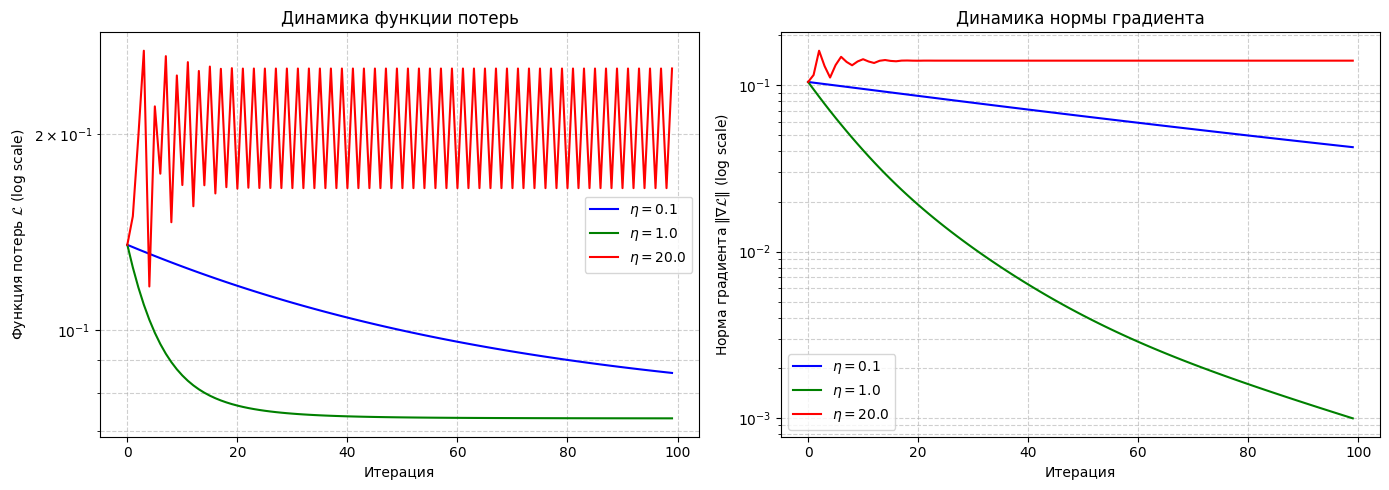

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Задание 9.1

etas = [0.1, 1.0, 20.0]
num_iterations = 100

# Словари для хранения историй
histories = {}

for eta in etas:
    # Начинаем из одной и той же начальной точки для каждого eta
    W_curr = W0.copy()
    b_curr = b0.copy()
    
    loss_hist = []
    grad_norm_hist = []
    increases = 0
    
    for r in range(num_iterations):
        # 1. Вычисляем функцию потерь и градиенты
        L_curr, grad_W, grad_b = backward(X, Y, W_curr, b_curr, lambda_reg)
        loss_hist.append(L_curr)
        
        # Норма полного градиента (объединяем W и b в один вектор)
        grad_norm = np.sqrt(np.linalg.norm(grad_W)**2 + np.linalg.norm(grad_b)**2)
        grad_norm_hist.append(grad_norm)
        
        # 2. Проверяем, увеличилась ли функция потерь по сравнению с предыдущим шагом
        if r > 0 and L_curr > loss_hist[-2]:
            increases += 1
            
        # 3. Обновляем параметры
        W_curr = W_curr - eta * grad_W
        b_curr = b_curr - eta * grad_b
        
    histories[eta] = {
        'loss': loss_hist,
        'grad_norm': grad_norm_hist,
        'increases': increases,
        'W_final': W_curr,
        'b_final': b_curr
    }

# Построение графиков в логарифмическом масштабе
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

colors = {0.1: 'blue', 1.0: 'green', 20.0: 'red'}
labels = {0.1: r'$\eta = 0.1$', 1.0: r'$\eta = 1.0$', 20.0: r'$\eta = 20.0$'}

for eta in etas:
    ax1.semilogy(histories[eta]['loss'], color=colors[eta], label=labels[eta])
    ax2.semilogy(histories[eta]['grad_norm'], color=colors[eta], label=labels[eta])

ax1.set_xlabel('Итерация')
ax1.set_ylabel(r'Функция потерь $\mathcal{L}$ (log scale)')
ax1.set_title('Динамика функции потерь')
ax1.legend()
ax1.grid(True, which="both", ls="--", alpha=0.6)

ax2.set_xlabel('Итерация')
ax2.set_ylabel(r'Норма градиента $\|\nabla \mathcal{L}\|$ (log scale)')
ax2.set_title('Динамика нормы градиента')
ax2.legend()
ax2.grid(True, which="both", ls="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [26]:
# Вывод точных чисел для таблицы отчёта
print(f"{'Шаг η':<6} | {'Начальное L':<12} | {'Конечное L':<12} | {'Мин. L':<12} | {'Итерация мин.':<14} | {'Увеличений'}")
print("-" * 85)

for eta in etas:
    hist = histories[eta]['loss']
    min_L = min(hist)
    min_iter = hist.index(min_L)
    increases = histories[eta]['increases']
    
    print(f"{eta:<6} | {hist[0]:<12.6f} | {hist[-1]:<12.6f} | {min_L:<12.6f} | {min_iter:<14} | {increases}")

Шаг η  | Начальное L  | Конечное L   | Мин. L       | Итерация мин.  | Увеличений
-------------------------------------------------------------------------------------
0.1    | 0.135239     | 0.085897     | 0.085897     | 99             | 0
1.0    | 0.135239     | 0.073134     | 0.073134     | 99             | 0
20.0   | 0.135239     | 0.252593     | 0.116682     | 4              | 51


**[Интерпретация]**
Анализ всей истории оптимизации (а не только последней точки) позволяет сделать следующие выводы:

1. **$\eta = 0.1$ (Медленное устойчивое уменьшение):** 
   Функция потерь и норма градиента монотонно убывают. Шаг достаточно мал, чтобы линейное приближение (касательная плоскость) точно предсказывало поведение функции. Однако сходимость к минимуму происходит медленно, и за 100 итераций алгоритм может не достичь дна "оврага".

2. **$\eta = 1.0$ (Быстрое устойчивое уменьшение):** 
   Оптимальный баланс. Функция потерь быстро падает в первые итерации, норма градиента стремительно уменьшается. Это наиболее эффективный режим градиентного спуска для данной задачи.

3. **$\eta = 20.0$ (Нестабильная траектория / Расходимость):** 
   Шаг слишком велик. Линейное приближение перестаёт быть адекватным на таком расстоянии. Алгоритм "перепрыгивает" через минимум, попадая в область с ещё большим значением функции потерь и более крутым градиентом. Это приводит к осцилляциям или экспоненциальному росту функции потерь (взрыву градиента). Наличие увеличений $\mathcal{L}$ (колонка "Увеличений" > 0) прямо указывает на эту нестабильность.

**Вывод:** Выбор шага обучения $\eta$ является критическим гиперпараметром. Слишком маленький шаг ведёт к неэффективным вычислениям, а слишком большой — к полной потере устойчивости оптимизации.

## 10. Итоговая карта понятий

### Задание 10.1. Один язык для всех операторов

**[Markdown] Связное резюме**

Основой математического анализа является **предел**, через который строго определяется **производная** как локальная скорость изменения скалярной функции одной переменной. Для малых приращений аргумента изменение функции линейно аппроксимируется с помощью понятия **дифференциал**. При переходе к функциям многих переменных скорость изменения по одной координате задаёт **частная производная**, а совокупность всех таких производных образует вектор **градиент**, указывающий направление наискорейшего роста функции. Если движение происходит вдоль произвольного единичного вектора, скорость изменения описывает **производная по направлению**, вычисляемая как скалярное произведение градиента и этого вектора. Когда аргументы функции сами зависят от других переменных, для учёта всех прямых и косвенных путей влияния применяется **полная производная**. 

Для векторных функций частные производные всех компонент выхода по всем компонентам входа собираются в матрицу, называемую **якобиан**. Чтобы избежать ресурсоёмкого явного построения полного якобиана в высоких размерностях, используются эффективные операторы: **JVP** (умножение якобиана на вектор справа) и **VJP** (умножение вектора-строки на якобиан слева). Эти операторы являются матричной реализацией **цепное правило** для композиций функций, что составляет математическую основу алгоритма обратного распространения ошибки. Для анализа локальной кривизны поверхности и классификации стационарных точек используется **гессиан** — симметричная матрица вторых частных производных, которая по сути является якобианом градиента. 

При работе с матричными параметрами удобно использовать **след** матрицы, так как он позволяет компактно записывать скалярные функции потерь и легко брать от них **матричный градиент** с помощью следовых тождеств. Любые аналитические выводы производных необходимо строго валидировать, для чего применяется **конечная разность** (например, центральная), сравнивающая аналитический результат с численным приближением по норме ошибки. Только после успешной численной проверки градиенты передаются в алгоритмы, такие как **численная оптимизация** (например, градиентный спуск). Эти алгоритмы итеративно обновляют параметры модели в направлении, противоположном градиенту, для минимизации целевой функции. Таким образом, все эти операторы образуют единую логическую цепь от базовых пределов до обучения сложных параметрических моделей.

**[Интерпретация] Сводная таблица операторов**

| Оператор | Тип входа | Тип выхода | Размерность | Какую чувствительность измеряет | Как проверяется численно |
|:---|:---|:---|:---|:---|:---|
| **Градиент** | Вектор $x \in \mathbb{R}^n$ | Вектор | $n \times 1$ | Скорость изменения скалярной функции по каждой координате | Центральная разность по каждой координате $x_i$ |
| **Якобиан** | Вектор $x \in \mathbb{R}^n$ | Матрица | $m \times n$ | Чувствительность каждого из $m$ выходов к каждому из $n$ входов | Покоординатная центральная разность для каждого выхода |
| **JVP** | Вектор $x$, вектор $v$ | Вектор | $m \times 1$ | Изменение векторной функции вдоль конкретного направления $v$ | Разность $f(x+\frac{h}{2}v) - f(x-\frac{h}{2}v)$, делённая на $h$ |
| **VJP** | Вектор $x$, вектор $u$ | Вектор | $n \times 1$ | Вклад скалярной чувствительности $u$ ко всем $n$ входным параметрам | Умножение транспонированного численного якобиана на $u$ |
| **Гессиан** | Вектор $x \in \mathbb{R}^n$ | Матрица | $n \times n$ | Скорость изменения градиента (локальную кривизну) вдоль пар координат | Центральная разность самих градиентов (вторые разности) |
| **Матричный градиент** | Матрица $W$ | Матрица | Как у $W$ | Чувствительность скалярной функции к изменению каждого элемента матрицы | Возмущение каждого элемента $W_{ij}$ на $\pm h/2$ |
| **Производная по направлению** | Вектор $x$, вектор $v$ | Скаляр | $1 \times 1$ | Скорость изменения функции вдоль единичного вектора $v$ | Разность $f(x+hv) - f(x)$, делённая на $h$ |
| **Полная производная** | Скаляр $t$ | Скаляр | $1 \times 1$ | Суммарную скорость изменения функции по всем путям зависимости от $t$ | Центральная разность композиции $F(t)$ по скаляру $t$ |

**[Интерпретация] Анализ сквозной функции**

1. **Суммы по индексам** возникли при вычислении линейного преобразования $Z_{nk} = \sum_{d=1}^D X_{nd} W_{dk} + b_k$ и при вычислении функции потерь $\mathcal{L} = \frac{1}{2N} \sum_{n,k} (H_{nk} - Y_{nk})^2 + \frac{\lambda}{2} \sum_{d,k} W_{dk}^2$.
2. **Поэлементное умножение** ($\odot$) использовалось при вычислении производной сигмоиды: $G_Z = G_H \odot H \odot (1 - H)$. Это необходимо, так как нелинейная функция применяется независимо к каждому элементу матрицы $Z$, и её производная не смешивает разные элементы между собой.
3. **Матричное произведение** применялось для эффективного вычисления прямого прохода $Z = XW + b$ (вместо вложенных циклов) и для распространения градиента назад: $\nabla_W \mathcal{L} = X^T G_Z$. Последнее автоматически выполняет суммирование по индексу наблюдений $n$, агрегируя вклад всех объектов пакета.
4. **Почему производная по $W$ имеет размер $3 \times 2$**: Матричный градиент скалярной функции по матрице параметров всегда имеет строго ту же размерность, что и сама матрица параметров. Поскольку $W \in \mathbb{R}^{3 \times 2}$ (3 входных признака, 2 выхода), то и $\nabla_W \mathcal{L}$ должен быть размером $3 \times 2$, чтобы каждый элемент $\frac{\partial \mathcal{L}}{\partial W_{dk}}$ показывал, как именно изменится потеря при изменении конкретного веса $W_{dk}$.